<a href="https://colab.research.google.com/github/Burzo572/dsb_project/blob/main/CapStoneProjectJankoBurzanovicEDA_Explained.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Importing Libraries

I imported the libraries needed for data manipulation, numerical operations, missing-value inspection, and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msn
import calendar

### Loading the Flood Dataset

I loaded the full multi-station dataset from its Parquet file. This gives me the environmental variables and flood labels needed to explore different locations before choosing a modeling station.

In [2]:
url = "https://github.com/Srabon-bot/Bangladesh-flood-data-set/raw/refs/heads/main/data/features/2026-08-07c/all_stations.parquet"
df = pd.read_parquet(url)

### Reviewing Data Types and Completeness

I used `info()` to inspect the number of records, data types, and non-null values in each column.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 839340 entries, 0 to 839339
Data columns (total 49 columns):
 #   Column                              Non-Null Count   Dtype         
---  ------                              --------------   -----         
 0   date                                839340 non-null  datetime64[ns]
 1   station_id                          839340 non-null  object        
 2   station_name                        839340 non-null  object        
 3   rainfall_local_mm                   839340 non-null  float64       
 4   rainfall_upstream_mm                839340 non-null  float64       
 5   soil_moisture_local                 839340 non-null  float64       
 6   river_discharge_m3s                 324322 non-null  float64       
 7   flood_byStor                        4563 non-null    float64       
 8   rainfall_local_mm_missing           839340 non-null  bool          
 9   rainfall_upstream_mm_missing        839340 non-null  bool          
 10  soil_moi

### Summary Statistics

I used `describe()` to review the distributions and ranges of numeric features and to look for unusually large or small values.

In [4]:
df.describe()

,date,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,flood_byStor,rainfall_local_mm_lag1d,rainfall_local_mm_lag2d,rainfall_local_mm_lag3d,rainfall_local_mm_lag5d,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_48h,flood_within_72h,upstream_chain_discharge_lag1d,upstream_reference_discharge_lag2d,upstream_chain_discharge_lag2d,upstream_reference_discharge_lag3d
count,839340,839340.000000,839340.000000,839340.000000,324322.000000,4563.000000,839310.000000,839280.000000,839250.000000,839190.000000,...,839340.000000,839340.000000,839340.000000,100850.000000,101282.000000,101704.000000,86478.000000,43236.000000,10809.000000,10808.000000
mean,1988-04-19 12:00:00,6.666148,6.593339,0.306508,8320.198070,10.405439,6.665985,6.665701,6.664963,6.664009,...,0.306381,13.593333,2.166667,0.142251,0.167779,0.190553,22230.667965,764.002652,1398.926811,763.905841
min,1950-01-01 00:00:00,0.000000,0.000000,0.010000,0.000000,0.000069,0.000000,0.000000,0.000000,0.000000,...,0.023446,0.000000,0.000000,0.000000,0.000000,0.000000,60.800000,276.330000,438.540000,276.330000
25%,1969-02-24 00:00:00,0.000000,0.188889,0.195000,64.920000,0.849906,0.000000,0.000000,0.000000,0.000000,...,0.210420,6.600000,0.000000,0.000000,0.000000,0.000000,3898.420000,355.450000,624.170000,355.450000
50%,1988-04-19 12:00:00,0.800000,2.800000,0.333000,525.020000,2.973004,0.800000,0.800000,0.800000,0.800000,...,0.323310,11.700000,0.900000,0.000000,0.000000,0.000000,10255.520000,538.510000,1063.140000,538.510000
75%,2007-06-14 00:00:00,8.200000,9.877778,0.413000,5034.010000,9.091566,8.200000,8.200000,8.200000,8.200000,...,0.403440,18.400000,2.400000,0.000000,0.000000,0.000000,33418.520000,1123.610000,2088.300000,1123.610000
max,2026-08-07 00:00:00,389.800000,143.466667,0.515000,164436.200000,251.121338,389.800000,389.800000,389.800000,389.800000,...,0.504734,35.800000,13.300000,1.000000,1.000000,1.000000,153107.720000,3242.400000,5779.960000,3242.400000
std,NaN,13.261082,9.271268,0.118658,18941.082592,21.997433,13.261190,13.261135,13.260118,13.259799,...,0.108680,9.131414,3.363862,0.349309,0.373672,0.392739,25753.366997,486.333016,870.479764,486.268225


### Listing the Variables

I listed the column names to understand which predictors, metadata fields, and flood labels are available.

In [5]:
df.columns

Index(['date', 'station_id', 'station_name', 'rainfall_local_mm',
       'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s',
       'flood_byStor', 'rainfall_local_mm_missing',
       'rainfall_upstream_mm_missing', 'soil_moisture_local_missing',
       'river_discharge_m3s_missing', 'flood_byStor_missing',
       'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d',
       'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d',
       'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d',
       'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d',
       'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d',
       'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d',
       'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d',
       'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d',
       'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d',
       'rainfall_local_mm_trend_ratio', 'rainfall_upstream_mm_sum7d',
       'rainfall_upstream

### Visualizing Missing Values

I created a missing-data matrix for important environmental variables and the flood target to see which fields have gaps and whether gaps occur together.

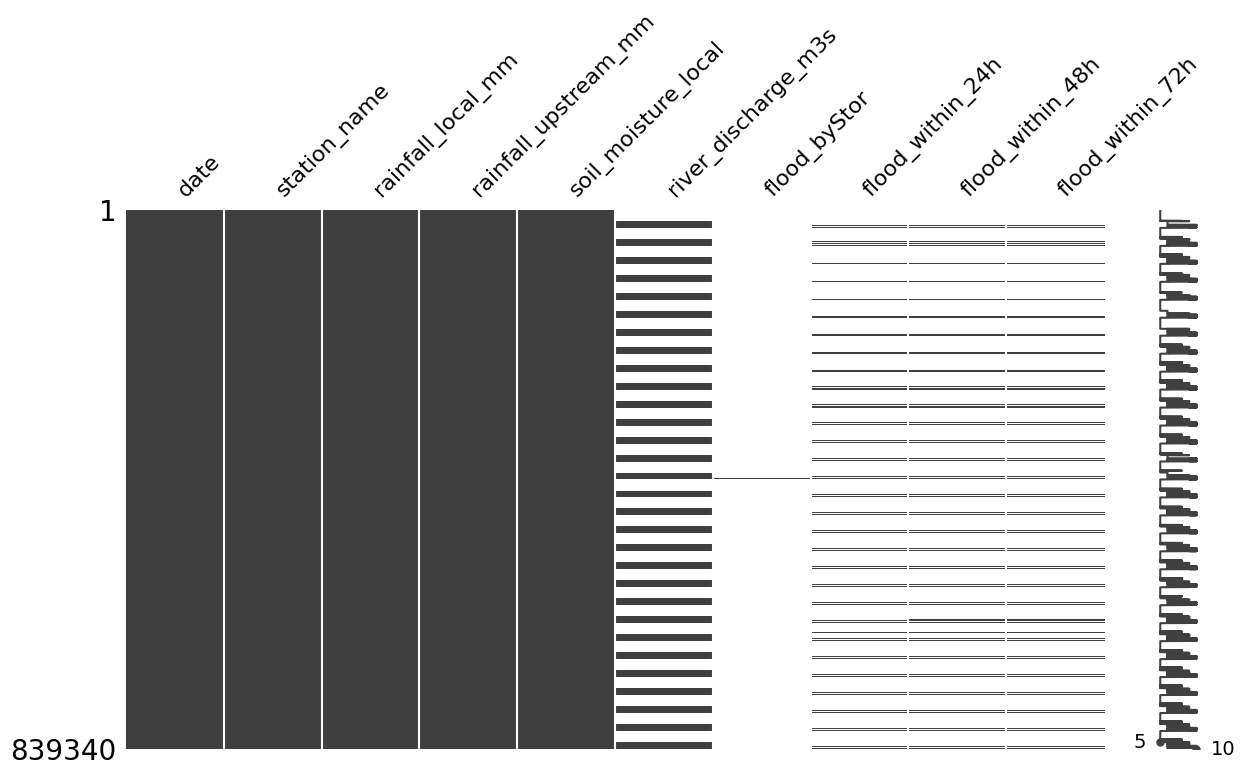

In [6]:
msn.matrix(df[[
        "date",
        "station_name",
        "rainfall_local_mm",
        "rainfall_upstream_mm",
        "soil_moisture_local",
        "river_discharge_m3s",
        "flood_byStor",
        "flood_within_24h",
        "flood_within_48h",
        "flood_within_72h"]],figsize=(14, 7));

### Initial Dataset Quality Check

I checked the dataset size, available columns, date range, and percentage of missing data for each variable.

In [7]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values (%):")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

print("\nFlood target distribution:")
print(df["flood_within_24h"].value_counts(dropna=False))

print("\nRows per station:")
print(df["station_id"].nunique())

print("\nSample:")
display(df.head())


Shape: (839340, 49)

Columns:
['date', 'station_id', 'station_name', 'rainfall_local_mm', 'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s', 'flood_byStor', 'rainfall_local_mm_missing', 'rainfall_upstream_mm_missing', 'soil_moisture_local_missing', 'river_discharge_m3s_missing', 'flood_byStor_missing', 'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d', 'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d', 'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d', 'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d', 'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d', 'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d', 'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d', 'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d', 'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d', 'rainfall_local_mm_trend_ratio', 'rainfall_upstream_mm_sum7d', 'rainfall_upstream_mm_sum14d', 'rainfall_upstream_mm_trend_ratio', 'soil_moisture_delta_30d', 'soil

,date,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,flood_byStor,rainfall_local_mm_missing,rainfall_upstream_mm_missing,...,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,upstream_chain_discharge_lag1d,upstream_reference_discharge_lag2d,upstream_chain_discharge_lag2d,upstream_reference_discharge_lag3d
0,1950-01-01,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.242,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
1,1950-01-02,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.240,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
2,1950-01-03,CH01,Rangamati (Karnaphuli),0.0,0.044444,0.238,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
3,1950-01-04,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.240,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN
4,1950-01-05,CH01,Rangamati (Karnaphuli),0.0,0.000000,0.238,NaN,NaN,False,False,...,NaN,None,NaN,None,NaN,None,NaN,NaN,NaN,NaN


### Understanding Target Labels Across Stations

I inspected the `flood_within_24h_label_regime` categories and counted known flood labels for each monitoring station. Label availability matters because not every row has a confirmed target.

In [8]:
# How the labels are made:
print("Label regimes:")
print(df["flood_within_24h_label_regime"].value_counts(dropna=False))

# How many labels are available per station?
station_labels = df.groupby("station_name").agg(total_rows=("flood_within_24h", "size"),known_labels=("flood_within_24h", "count"),flood_cases=("flood_within_24h", "sum"))

print("\nLabels per station:")
display(station_labels.sort_values("known_labels", ascending=False))


Label regimes:
flood_within_24h_label_regime
None                   738490
observed                91350
unobserved_positive      9500
Name: count, dtype: int64

Labels per station:


,total_rows,known_labels,flood_cases
station_name,,,
Chilmari,27978,3688,743.0
Hardinge Bridge (Kushtia),27978,3688,746.0
Amalshid,27978,3598,747.0
Sherpur (Sylhet),27978,3586,726.0
Sylhet,27978,3563,724.0
Sariakandi,27978,3550,628.0
Sirajganj,27978,3547,585.0
Mawa,27978,3526,665.0
Bahadurabad,27978,3525,606.0


### Checking When Flood Labels Are Available

I grouped the dataset by year to see how many known flood labels and positive cases are available over time.

In [9]:
# In which years do we have known labels?
df["year"] = df["date"].dt.year

year_labels = df.groupby("year").agg(known_labels=("flood_within_24h", "count"),flood_cases=("flood_within_24h", "sum"))

print("\nLabels by year:")
display(year_labels[year_labels["known_labels"] > 0])


Labels by year:


,known_labels,flood_cases
year,,
1985,166,166.0
1986,67,67.0
1987,640,640.0
1988,570,570.0
1989,74,74.0
1990,543,543.0
1991,348,348.0
1992,1,1.0
1994,39,39.0


### Selecting Observed Flood Labels

I kept rows whose 24-hour flood label is marked as `observed` and converted the target to an integer. This avoids treating unknown labels as confirmed non-flood days.

In [10]:
# Keep only rows with observed labels
df_model = df[df["flood_within_24h_label_regime"] == "observed"].copy()

# Convert target to integer
df_model["flood_within_24h"] = (df_model["flood_within_24h"].astype(int))

# Check target distribution
print(df_model["flood_within_24h"].value_counts())

flood_within_24h
0    86504
1     4846
Name: count, dtype: int64


### Flood and Non-Flood Cases by Year

I compared the number of positive and negative observed labels for each year to identify periods useful for binary classification.

In [11]:
# Check labels by year
year_check = df_model.groupby("year").agg(total_rows=("flood_within_24h", "size"), flood_cases=("flood_within_24h", "sum"))

year_check["no_flood_cases"] = (year_check["total_rows"] - year_check["flood_cases"])

display(year_check)

,total_rows,flood_cases,no_flood_cases
year,,,
2012,30,0,30
2013,10950,377,10573
2014,10950,491,10459
2015,10950,1288,9662
2016,2700,4,2696
2020,30,0,30
2021,10950,515,10435
2022,10950,655,10295
2023,10950,542,10408


### Creating an Exploratory Time-Window Subset

I temporarily restricted the observed-label data to a defined period and sorted it by date and station. This subset supports the initial comparisons below; it does **not** define the final period or station selection.

In [12]:
# Keep observed labels from 2021 to 2025
df_model = df[(df["flood_within_24h_label_regime"] == "observed") & (df["year"].between(2021, 2025))].copy()

# Sort chronologically
df_model = df_model.sort_values(["date", "station_id"]).reset_index(drop=True)

### Checking the Filtered Data

I verified the filtered dataset dimensions, its dates, the target distribution, and remaining missing values.

In [13]:
print("Shape:", df_model.shape)
print("Date range:", df_model["date"].min(), "to", df_model["date"].max())

print("\nTarget distribution:")
print(df_model["flood_within_24h"].value_counts())

print("\nMissing values in columns:")
print(df_model.isna().sum().sort_values(ascending=False))

Shape: (54780, 50)
Date range: 2021-01-01 00:00:00 to 2025-12-31 00:00:00

Target distribution:
flood_within_24h
0.0    52094
1.0     2686
Name: count, dtype: int64

Missing values in columns:
upstream_chain_discharge_lag2d        52954
upstream_reference_discharge_lag3d    52954
flood_byStor                          52106
upstream_reference_discharge_lag2d    47476
upstream_chain_discharge_lag1d        40172
rainfall_local_mm_trend_ratio         12626
rainfall_upstream_mm_trend_ratio       1872
station_name                              0
station_id                                0
rainfall_upstream_mm_missing              0
soil_moisture_local_missing               0
river_discharge_m3s_missing               0
rainfall_upstream_mm                      0
rainfall_local_mm                         0
soil_moisture_local                       0
river_discharge_m3s                       0
rainfall_local_mm_missing                 0
date                                      0
rainfall_upstre

### Checking Duplicate Records

I checked for exact duplicate rows so repeated records do not distort the analysis.

In [14]:
# Check duplicate rows
print("Duplicate rows:", df_model.duplicated().sum())

Duplicate rows: 0


### Measuring Missingness

I calculated missing-value percentages to identify variables that may need to be excluded or handled before modeling.

In [15]:
# Check missing values as percentages
missing_pct = (df_model.isna().mean() * 100).sort_values(ascending=False)

display(missing_pct)

,0
upstream_chain_discharge_lag2d,96.666667
upstream_reference_discharge_lag3d,96.666667
flood_byStor,95.118656
upstream_reference_discharge_lag2d,86.666667
upstream_chain_discharge_lag1d,73.333333
rainfall_local_mm_trend_ratio,23.048558
rainfall_upstream_mm_trend_ratio,3.417306
station_name,0.000000
station_id,0.000000
rainfall_upstream_mm_missing,0.000000


### Checking the Filtered Data Structure

I reviewed column types and non-null counts after filtering the dataset.

In [16]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54780 entries, 0 to 54779
Data columns (total 50 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   date                                54780 non-null  datetime64[ns]
 1   station_id                          54780 non-null  object        
 2   station_name                        54780 non-null  object        
 3   rainfall_local_mm                   54780 non-null  float64       
 4   rainfall_upstream_mm                54780 non-null  float64       
 5   soil_moisture_local                 54780 non-null  float64       
 6   river_discharge_m3s                 54780 non-null  float64       
 7   flood_byStor                        2674 non-null   float64       
 8   rainfall_local_mm_missing           54780 non-null  bool          
 9   rainfall_upstream_mm_missing        54780 non-null  bool          
 10  soil_moisture_local_mi

### Reviewing Candidate Features

I listed the columns again to identify useful local and upstream predictors.

In [17]:
df_model.columns

Index(['date', 'station_id', 'station_name', 'rainfall_local_mm',
       'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s',
       'flood_byStor', 'rainfall_local_mm_missing',
       'rainfall_upstream_mm_missing', 'soil_moisture_local_missing',
       'river_discharge_m3s_missing', 'flood_byStor_missing',
       'rainfall_local_mm_lag1d', 'rainfall_local_mm_lag2d',
       'rainfall_local_mm_lag3d', 'rainfall_local_mm_lag5d',
       'rainfall_upstream_mm_lag1d', 'rainfall_upstream_mm_lag2d',
       'rainfall_upstream_mm_lag3d', 'rainfall_upstream_mm_lag5d',
       'soil_moisture_local_lag1d', 'soil_moisture_local_lag2d',
       'soil_moisture_local_lag3d', 'soil_moisture_local_lag5d',
       'river_discharge_m3s_lag1d', 'river_discharge_m3s_lag2d',
       'river_discharge_m3s_lag3d', 'river_discharge_m3s_lag5d',
       'rainfall_local_mm_sum7d', 'rainfall_local_mm_sum14d',
       'rainfall_local_mm_trend_ratio', 'rainfall_upstream_mm_sum7d',
       'rainfall_upstream

### Removing Selected Columns

I removed selected columns from the exploratory dataset and checked the missing values that remain. These choices are part of the EDA subset, not necessarily the final feature set for Models A, B, and C.

In [18]:
# Columns to exclude
cols_to_drop = ["upstream_chain_discharge_lag2d",
    "upstream_reference_discharge_lag3d",
    "flood_byStor",
    "upstream_reference_discharge_lag2d",
    "upstream_chain_discharge_lag1d",
    "rainfall_local_mm_trend_ratio"]

df_clean = df_model.drop(columns=cols_to_drop)

print("Shape:", df_clean.shape)

# Check remaining missing values
missing = df_clean.isna().sum()
display(missing[missing > 0].sort_values(ascending=False))

Shape: (54780, 44)


,0
rainfall_upstream_mm_trend_ratio,1872


### Checking a Remaining Missing Feature

I counted missing values in the upstream rainfall trend-ratio column before deciding whether to retain it.

In [19]:
df_clean["rainfall_upstream_mm_trend_ratio"].isna().sum()

np.int64(1872)

### Dropping the Trend-Ratio Column

I removed this column from the exploratory dataset and checked its new shape.

In [20]:
df_clean = df_clean.drop(columns=["rainfall_upstream_mm_trend_ratio"])

print("Shape:", df_clean.shape)

Shape: (54780, 43)


### Verifying Missing Values After Cleaning

I counted missing values in every remaining column to see whether the current exploratory table is complete.

In [21]:
missing = df_clean.isna().sum()

print(missing)

date                             0
station_id                       0
station_name                     0
rainfall_local_mm                0
rainfall_upstream_mm             0
soil_moisture_local              0
river_discharge_m3s              0
rainfall_local_mm_missing        0
rainfall_upstream_mm_missing     0
soil_moisture_local_missing      0
river_discharge_m3s_missing      0
flood_byStor_missing             0
rainfall_local_mm_lag1d          0
rainfall_local_mm_lag2d          0
rainfall_local_mm_lag3d          0
rainfall_local_mm_lag5d          0
rainfall_upstream_mm_lag1d       0
rainfall_upstream_mm_lag2d       0
rainfall_upstream_mm_lag3d       0
rainfall_upstream_mm_lag5d       0
soil_moisture_local_lag1d        0
soil_moisture_local_lag2d        0
soil_moisture_local_lag3d        0
soil_moisture_local_lag5d        0
river_discharge_m3s_lag1d        0
river_discharge_m3s_lag2d        0
river_discharge_m3s_lag3d        0
river_discharge_m3s_lag5d        0
rainfall_local_mm_su

### Reviewing Cleaned Column Types

I checked the resulting DataFrame structure after removing selected variables.

In [22]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54780 entries, 0 to 54779
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   date                           54780 non-null  datetime64[ns]
 1   station_id                     54780 non-null  object        
 2   station_name                   54780 non-null  object        
 3   rainfall_local_mm              54780 non-null  float64       
 4   rainfall_upstream_mm           54780 non-null  float64       
 5   soil_moisture_local            54780 non-null  float64       
 6   river_discharge_m3s            54780 non-null  float64       
 7   rainfall_local_mm_missing      54780 non-null  bool          
 8   rainfall_upstream_mm_missing   54780 non-null  bool          
 9   soil_moisture_local_missing    54780 non-null  bool          
 10  river_discharge_m3s_missing    54780 non-null  bool          
 11  flood_byStor_mi

### Describing Cleaned Features

I reviewed numerical summary statistics after the initial cleaning steps.

In [23]:
df_clean.describe()

,date,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_lag1d,rainfall_local_mm_lag2d,rainfall_local_mm_lag3d,rainfall_local_mm_lag5d,rainfall_upstream_mm_lag1d,...,rainfall_upstream_mm_sum7d,rainfall_upstream_mm_sum14d,soil_moisture_delta_30d,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_48h,flood_within_72h,year
count,54780,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,...,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000,54780.000000
mean,2023-07-02 11:59:59.999999744,6.155283,6.048228,0.308205,8071.885354,6.155283,6.155257,6.155257,6.155248,6.048207,...,42.335196,84.667082,0.000052,0.308068,13.593333,2.166667,0.049032,0.072417,0.093428,2023.000548
min,2021-01-01 00:00:00,0.000000,0.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-0.359000,0.031204,0.000000,0.000000,0.000000,0.000000,0.000000,2021.000000
25%,2022-04-02 00:00:00,0.000000,0.100000,0.220000,61.950000,0.000000,0.000000,0.000000,0.000000,0.100000,...,2.211111,6.688889,-0.055000,0.233468,6.600000,0.000000,0.000000,0.000000,0.000000,2022.000000
50%,2023-07-02 12:00:00,0.400000,2.277778,0.319000,476.530000,0.400000,0.400000,0.400000,0.400000,2.277778,...,24.600000,54.900000,-0.002000,0.315499,11.700000,0.900000,0.000000,0.000000,0.000000,2023.000000
75%,2024-10-01 00:00:00,7.000000,9.022222,0.401000,4796.330000,7.000000,7.000000,7.000000,7.000000,9.022222,...,69.055556,146.911111,0.049000,0.386711,18.400000,2.400000,0.000000,0.000000,0.000000,2024.000000
max,2025-12-31 00:00:00,389.800000,95.166667,0.514000,131824.640000,389.800000,389.800000,389.800000,389.800000,95.166667,...,318.000000,460.022222,0.378000,0.503450,35.800000,13.300000,1.000000,1.000000,1.000000,2025.000000
std,NaN,13.026416,8.744743,0.108595,18124.608509,13.026416,13.026428,13.026428,13.026432,8.744757,...,48.155285,87.133671,0.092507,0.095833,9.131492,3.363891,0.215938,0.259179,0.291034,1.414033


### Using Date as the Index

I set `date` as the index to make chronological inspection and time-series comparisons easier.

In [24]:
df_clean = df_clean.set_index("date")

### Previewing the Cleaned Dataset

I displayed the first rows to confirm that the data and date index look correct.

In [25]:
df_clean.head()

,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_missing,rainfall_upstream_mm_missing,soil_moisture_local_missing,river_discharge_m3s_missing,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,year
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,CH01,Rangamati (Karnaphuli),0.0,0.0,0.297,206.49,False,False,False,False,...,0.317899,35.8,7.8,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CH02,Bandarban (Sangu),0.0,0.0,0.212,49.23,False,False,False,False,...,0.224850,22.1,1.4,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CH03,Chittagong (Halda),0.0,0.0,0.172,256.63,False,False,False,False,...,0.191675,5.0,0.8,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CO01,Barisal,0.0,0.0,0.223,10.02,False,False,False,False,...,0.249996,7.3,0.4,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CO02,Khulna (Rupsha),0.0,0.0,0.276,124.89,False,False,False,False,...,0.287952,4.8,0.0,0.0,observed,0.0,observed,0.0,observed,2021


### River Discharge and Flood Labels by Station

I used a scatter plot to compare estimated river discharge across stations, colored by the 24-hour flood label. This is an exploratory comparison; it does not establish a discharge threshold or a causal relationship.

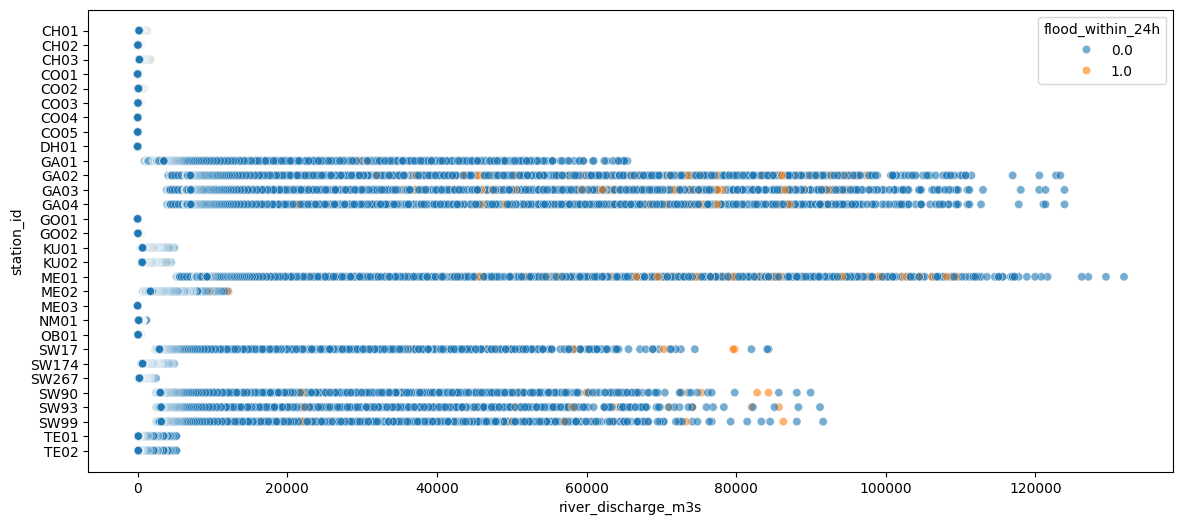

In [26]:
"""This scatter plot shows the relationship between river discharge and flood events at different stations.
Blue dots represent no flood, while orange dots represent flood events within 24 hours.
We can see that some stations have much higher river discharge values than others.
However, high river discharge does not always mean a flood will happen.
This means we need other features to improve flood prediction."""

figure, axis = plt.subplots(figsize=(14, 6))

sns.scatterplot(
     df_clean
    ,x="river_discharge_m3s"
    ,y="station_id"
    ,hue="flood_within_24h"
    ,alpha=0.6);

### Correlation Between Environmental Features

I plotted a correlation matrix for selected rainfall, soil moisture, discharge, geographic variables, and the target. Correlations describe relationships in this subset but do not by themselves show predictive performance.

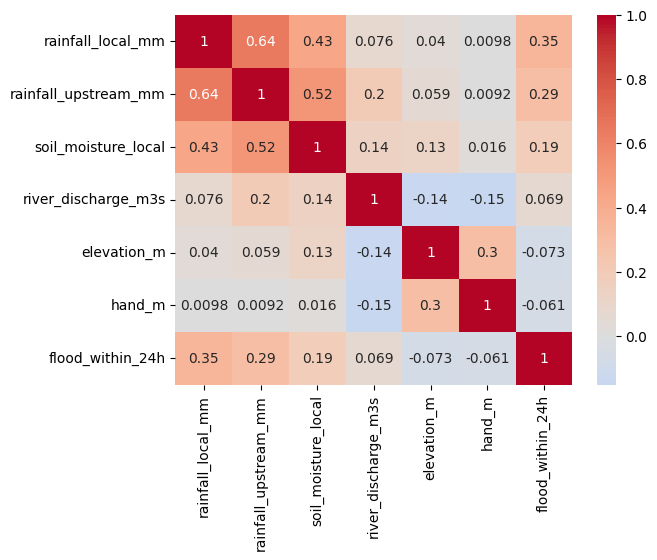

In [27]:
"""This heatmap shows the correlation between different environmental factors and flood events.
Red colors represent positive correlations, while blue colors represent negative correlations.
We can see that local rainfall has the strongest positive correlation with floods, at 0.35.
Upstream rainfall also shows a positive correlation of 0.29.
Soil moisture has a weaker correlation, while river discharge has a very weak correlation.
This suggests that rainfall is an important factor to consider when predicting floods."""

cols = [
    "rainfall_local_mm",
    "rainfall_upstream_mm",
    "soil_moisture_local",
    "river_discharge_m3s",
    "elevation_m",
    "hand_m",
    "flood_within_24h"]

sns.heatmap(df_clean[cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.show()

### Inspecting Columns Before Station Analysis

I checked the available columns before investigating station-level patterns.

In [28]:
df_clean.columns

Index(['station_id', 'station_name', 'rainfall_local_mm',
       'rainfall_upstream_mm', 'soil_moisture_local', 'river_discharge_m3s',
       'rainfall_local_mm_missing', 'rainfall_upstream_mm_missing',
       'soil_moisture_local_missing', 'river_discharge_m3s_missing',
       'flood_byStor_missing', 'rainfall_local_mm_lag1d',
       'rainfall_local_mm_lag2d', 'rainfall_local_mm_lag3d',
       'rainfall_local_mm_lag5d', 'rainfall_upstream_mm_lag1d',
       'rainfall_upstream_mm_lag2d', 'rainfall_upstream_mm_lag3d',
       'rainfall_upstream_mm_lag5d', 'soil_moisture_local_lag1d',
       'soil_moisture_local_lag2d', 'soil_moisture_local_lag3d',
       'soil_moisture_local_lag5d', 'river_discharge_m3s_lag1d',
       'river_discharge_m3s_lag2d', 'river_discharge_m3s_lag3d',
       'river_discharge_m3s_lag5d', 'rainfall_local_mm_sum7d',
       'rainfall_local_mm_sum14d', 'rainfall_upstream_mm_sum7d',
       'rainfall_upstream_mm_sum14d', 'soil_moisture_delta_30d',
       'soil_moisture_sw

### Listing Station Identifiers

I identified the monitoring-station codes present in the cleaned exploratory dataset.

In [29]:
df_clean["station_id"].unique()

array(['CH01', 'CH02', 'CH03', 'CO01', 'CO02', 'CO03', 'CO04', 'CO05',
       'DH01', 'GA01', 'GA02', 'GA03', 'GA04', 'GO01', 'GO02', 'KU01',
       'KU02', 'ME01', 'ME02', 'ME03', 'NM01', 'OB01', 'SW17', 'SW174',
       'SW267', 'SW90', 'SW93', 'SW99', 'TE01', 'TE02'], dtype=object)

### Inspecting Positive Labels at One Station

I isolated positive flood-label rows for station CH01 to inspect their frequency and individual records.

In [30]:
# From 1826 rows only 63 shows that floods occured for CH01 monitoring station

df_clean[(df_clean["station_id"] == "CH01") &(df_clean["flood_within_24h"] == 1)]


,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_missing,rainfall_upstream_mm_missing,soil_moisture_local_missing,river_discharge_m3s_missing,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,year
date,,,,,,,,,,,,,,,,,,,,,
2022-08-22,CH01,Rangamati (Karnaphuli),27.7,17.344444,0.416,192.64,False,False,False,False,...,0.396354,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2022
2023-07-24,CH01,Rangamati (Karnaphuli),6.5,5.577778,0.375,173.58,False,False,False,False,...,0.365090,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
2023-07-25,CH01,Rangamati (Karnaphuli),4.1,11.266667,0.391,173.58,False,False,False,False,...,0.366825,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
2023-07-31,CH01,Rangamati (Karnaphuli),6.9,20.033333,0.385,175.20,False,False,False,False,...,0.371873,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
2023-08-07,CH01,Rangamati (Karnaphuli),74.5,61.111111,0.430,194.88,False,False,False,False,...,0.390588,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-09-15,CH01,Rangamati (Karnaphuli),5.9,7.955556,0.415,1190.24,False,False,False,False,...,0.410938,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2024
2024-09-20,CH01,Rangamati (Karnaphuli),1.5,3.933333,0.382,1215.19,False,False,False,False,...,0.404430,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2024
2024-09-23,CH01,Rangamati (Karnaphuli),3.2,12.577778,0.401,1149.80,False,False,False,False,...,0.400783,35.8,7.8,1.0,observed,1.0,observed,1.0,observed,2024


### Confirming Data Types

I reviewed the DataFrame structure before examining target balance and distributions.

In [31]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 54780 entries, 2021-01-01 to 2025-12-31
Data columns (total 42 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   station_id                     54780 non-null  object 
 1   station_name                   54780 non-null  object 
 2   rainfall_local_mm              54780 non-null  float64
 3   rainfall_upstream_mm           54780 non-null  float64
 4   soil_moisture_local            54780 non-null  float64
 5   river_discharge_m3s            54780 non-null  float64
 6   rainfall_local_mm_missing      54780 non-null  bool   
 7   rainfall_upstream_mm_missing   54780 non-null  bool   
 8   soil_moisture_local_missing    54780 non-null  bool   
 9   river_discharge_m3s_missing    54780 non-null  bool   
 10  flood_byStor_missing           54780 non-null  bool   
 11  rainfall_local_mm_lag1d        54780 non-null  float64
 12  rainfall_local_mm_lag2d      

### Reviewing Flood Class Balance

I counted flood and non-flood labels and checked their proportions. An imbalanced target requires careful metrics beyond accuracy.

In [32]:
print(df_clean["flood_within_24h"].value_counts())
print(df_clean["flood_within_24h"].value_counts(normalize=True) * 100)

print("\nLabel regime:")
print(df_clean["flood_within_24h_label_regime"].value_counts())

flood_within_24h
0.0    52094
1.0     2686
Name: count, dtype: int64
flood_within_24h
0.0    95.096751
1.0     4.903249
Name: proportion, dtype: float64

Label regime:
flood_within_24h_label_regime
observed    54780
Name: count, dtype: int64


### Soil Moisture by Flood Class

I compared soil-moisture distributions for observed non-flood and flood cases using boxplots to see whether the two groups differ.

Text(0, 0.5, 'Local Soil Moisture')

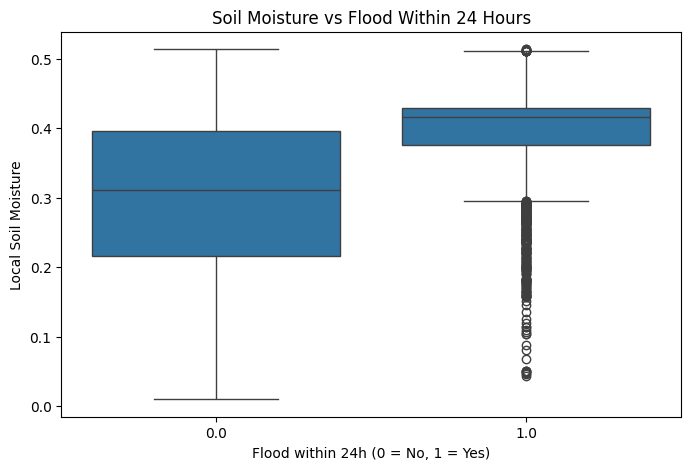

In [33]:
# The boxplot compares local soil moisture measurements between observations with and without a recorded flood event within the next 24 hours.
# It allows us to compare the median, spread, and overall distribution of soil moisture for both target classes.
# This is useful for investigating whether wetter soil conditions are associated with a higher likelihood of flooding.

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="flood_within_24h", y="soil_moisture_local")

plt.title("Soil Moisture vs Flood Within 24 Hours")
plt.xlabel("Flood within 24h (0 = No, 1 = Yes)")
plt.ylabel("Local Soil Moisture")

### Visualizing Class Imbalance

I plotted the frequency of each target class to see how rare the positive flood cases are in the current sample.

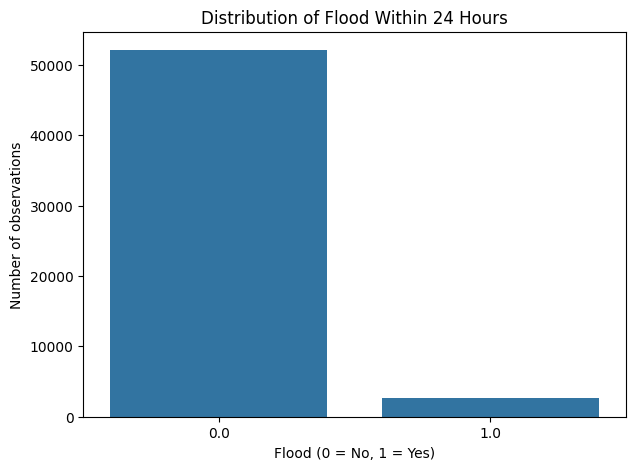

In [34]:
# The dataset contains a significant class imbalance, with approximately 95.1% of observations belonging to the non-flood class and 4.9% belonging to the flood class.
# This imbalance is important for model development and evaluation. A model could achieve high accuracy simply by predicting the majority class, while failing to identify actual flood events.
# Therefore, metrics such as Recall, Precision, and F1-score will be particularly important when evaluating model performance.

plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='flood_within_24h')

plt.title('Distribution of Flood Within 24 Hours')
plt.xlabel('Flood (0 = No, 1 = Yes)')
plt.ylabel('Number of observations')

plt.show()

### Inspecting Feature Distributions

I used histograms to examine the spread, skewness, and potential outliers of rainfall, soil moisture, estimated discharge, and geographic variables.

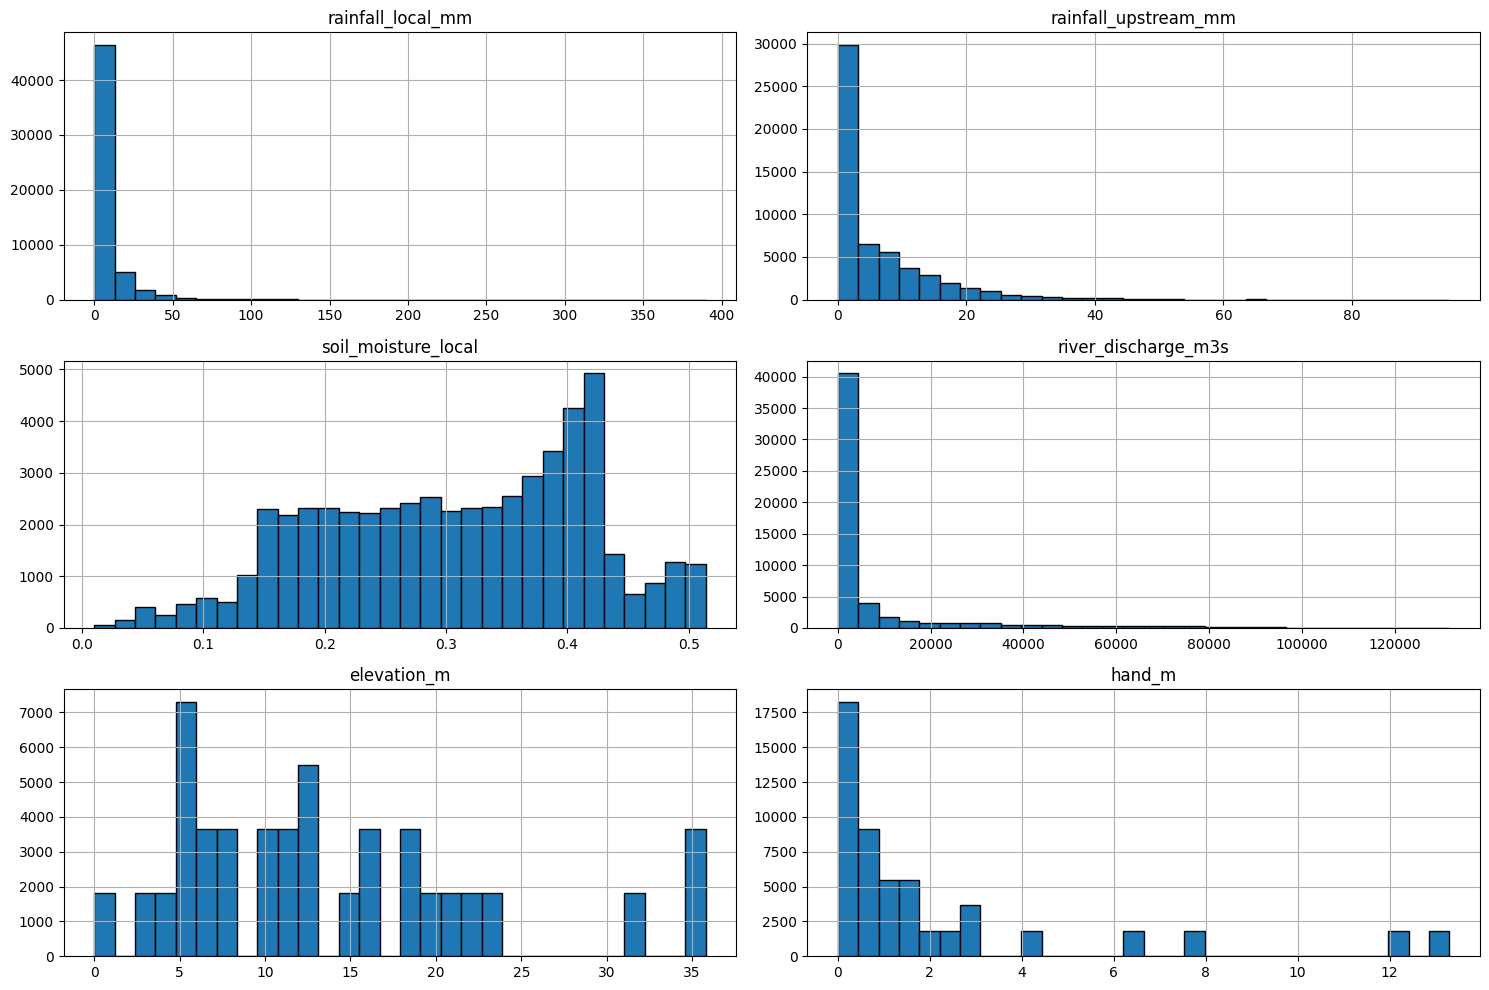

In [35]:
# Histograms were used to examine the distributions of six numerical features.
# These visualizations provide an overview of the data distributions and help identify potential skewness, extreme values, and differences in variability across features.
selected_cols = [
    'rainfall_local_mm',
    'rainfall_upstream_mm',
    'soil_moisture_local',
    'river_discharge_m3s',
    'elevation_m',
    'hand_m']

df_clean[selected_cols].hist(bins=30, figsize=(15, 10), edgecolor='black')

plt.tight_layout()
plt.show()

### Checking Data Before Basin Comparison

I inspected the dataset structure before assigning stations to river basins.

In [36]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 54780 entries, 2021-01-01 to 2025-12-31
Data columns (total 42 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   station_id                     54780 non-null  object 
 1   station_name                   54780 non-null  object 
 2   rainfall_local_mm              54780 non-null  float64
 3   rainfall_upstream_mm           54780 non-null  float64
 4   soil_moisture_local            54780 non-null  float64
 5   river_discharge_m3s            54780 non-null  float64
 6   rainfall_local_mm_missing      54780 non-null  bool   
 7   rainfall_upstream_mm_missing   54780 non-null  bool   
 8   soil_moisture_local_missing    54780 non-null  bool   
 9   river_discharge_m3s_missing    54780 non-null  bool   
 10  flood_byStor_missing           54780 non-null  bool   
 11  rainfall_local_mm_lag1d        54780 non-null  float64
 12  rainfall_local_mm_lag2d      

### Previewing Records Before Basin Mapping

I reviewed the records before adding the basin category.

In [37]:
df_clean.head()

,station_id,station_name,rainfall_local_mm,rainfall_upstream_mm,soil_moisture_local,river_discharge_m3s,rainfall_local_mm_missing,rainfall_upstream_mm_missing,soil_moisture_local_missing,river_discharge_m3s_missing,...,soil_moisture_swi,elevation_m,hand_m,flood_within_24h,flood_within_24h_label_regime,flood_within_48h,flood_within_48h_label_regime,flood_within_72h,flood_within_72h_label_regime,year
date,,,,,,,,,,,,,,,,,,,,,
2021-01-01,CH01,Rangamati (Karnaphuli),0.0,0.0,0.297,206.49,False,False,False,False,...,0.317899,35.8,7.8,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CH02,Bandarban (Sangu),0.0,0.0,0.212,49.23,False,False,False,False,...,0.224850,22.1,1.4,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CH03,Chittagong (Halda),0.0,0.0,0.172,256.63,False,False,False,False,...,0.191675,5.0,0.8,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CO01,Barisal,0.0,0.0,0.223,10.02,False,False,False,False,...,0.249996,7.3,0.4,0.0,observed,0.0,observed,0.0,observed,2021
2021-01-01,CO02,Khulna (Rupsha),0.0,0.0,0.276,124.89,False,False,False,False,...,0.287952,4.8,0.0,0.0,observed,0.0,observed,0.0,observed,2021


### Mapping Stations to River Basins

I assigned each station ID to one of the basin groups used in this exploratory comparison. This manual mapping should be checked against authoritative station and river-network metadata before final modeling.

In [38]:
# Map each station to its corresponding river basin

basin_mapping = {
    # Brahmaputra basin
    "SW90": "brahmaputra",
    "SW93": "brahmaputra",
    "SW99": "brahmaputra",
    "SW17": "brahmaputra",
    "TE01": "brahmaputra",
    "TE02": "brahmaputra",
    "OB01": "brahmaputra",
    "DH01": "brahmaputra",

    # Ganges basin
    "GA01": "ganges",
    "GA02": "ganges",
    "GA03": "ganges",
    "GA04": "ganges",
    "GO01": "ganges",
    "GO02": "ganges",
    "CO01": "ganges",
    "CO02": "ganges",
    "CO03": "ganges",
    "CO04": "ganges",

    # Meghna basin
    "ME01": "meghna",
    "ME02": "meghna",
    "ME03": "meghna",
    "SW267": "meghna",
    "SW174": "meghna",
    "KU01": "meghna",
    "KU02": "meghna",
    "NM01": "meghna",

    # Chittagong Hill Tracts basin
    "CH01": "cht",
    "CH02": "cht",
    "CH03": "cht",
    "CO05": "cht"
}

# Add basin column
df_clean["basin"] = df_clean["station_id"].map(basin_mapping)


### Confirming Basin Assignments

I displayed station identifiers, station names, and mapped basins to check the assignment.

In [39]:
df_clean[["station_id", "station_name", "basin"]].head(10)

,station_id,station_name,basin
date,,,
2021-01-01,CH01,Rangamati (Karnaphuli),cht
2021-01-01,CH02,Bandarban (Sangu),cht
2021-01-01,CH03,Chittagong (Halda),cht
2021-01-01,CO01,Barisal,ganges
2021-01-01,CO02,Khulna (Rupsha),ganges
2021-01-01,CO03,Bagerhat,ganges
2021-01-01,CO04,Patuakhali,ganges
2021-01-01,CO05,Cox's Bazar,cht
2021-01-01,DH01,Kurigram (Dharla),brahmaputra


### Counting Stations by Basin

I counted unique stations in each basin to understand the different sizes of the monitoring groups.

In [40]:
df_clean.groupby("basin")["station_id"].nunique()

,station_id
basin,
brahmaputra,8
cht,4
ganges,10
meghna,8


### Checking Unmapped Stations

I counted rows with a missing basin assignment to detect station IDs absent from the mapping.

In [41]:
df_clean["basin"].isna().sum()

np.int64(0)

### Checking Data After Basin Mapping

I reviewed the DataFrame and confirmed that the new basin field is present.

In [42]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 54780 entries, 2021-01-01 to 2025-12-31
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   station_id                     54780 non-null  object 
 1   station_name                   54780 non-null  object 
 2   rainfall_local_mm              54780 non-null  float64
 3   rainfall_upstream_mm           54780 non-null  float64
 4   soil_moisture_local            54780 non-null  float64
 5   river_discharge_m3s            54780 non-null  float64
 6   rainfall_local_mm_missing      54780 non-null  bool   
 7   rainfall_upstream_mm_missing   54780 non-null  bool   
 8   soil_moisture_local_missing    54780 non-null  bool   
 9   river_discharge_m3s_missing    54780 non-null  bool   
 10  flood_byStor_missing           54780 non-null  bool   
 11  rainfall_local_mm_lag1d        54780 non-null  float64
 12  rainfall_local_mm_lag2d      

### Previewing Basin Categories

I inspected the mapped basin values.

In [43]:
df_clean["basin"].head()

,basin
date,
2021-01-01,cht
2021-01-01,cht
2021-01-01,cht
2021-01-01,ganges
2021-01-01,ganges


### Comparing Flood Observations Between Basins

I calculated the number of stations, observed target records, positive flood labels, and flood-label rate for each mapped basin. Counts and rates should be considered together because basin sample sizes differ.

In [44]:

basin_floods = (
    df_clean.groupby("basin")
    .agg(
        stations=("station_id", "nunique"),
        total_observations=("flood_within_24h", "count"),
        flood_observations=("flood_within_24h", "sum"),
        flood_rate=("flood_within_24h", "mean")).reset_index())

basin_floods["flood_rate"] = (basin_floods["flood_rate"] * 100)

basin_floods = basin_floods.sort_values(by="flood_observations",ascending=False)

basin_floods


,basin,stations,total_observations,flood_observations,flood_rate
2,ganges,10,18260,1362.0,7.458927
3,meghna,8,14608,715.0,4.894578
0,brahmaputra,8,14608,316.0,2.163198
1,cht,4,7304,293.0,4.011501


Flood Observations by River Basin

The analysis of flood observations across the four major river basins revealed differences in recorded flood occurrence.

The Ganges basin recorded the highest number of positive flood observations (1,362), with a flood rate of approximately 7.46%. The Meghna basin followed with 715 observations (4.89%), while the Chittagong Hill Tracts (CHT) recorded 293 (4.01%). The Brahmaputra basin had the lowest flood rate, with 316 positive observations (2.16%).

Since the number of monitoring stations differs between basins, flood rates provide a more meaningful comparison than raw observation counts alone.

These findings suggest that flood occurrence patterns vary across the river basins and support further investigation into the relationship between hydrological conditions and flood events.

### Plotting Flood Observations by Basin

I used a bar chart to compare the number of positive flood labels in each basin in the exploratory subset. A higher count alone does not prove a basin is more suitable for forecasting.

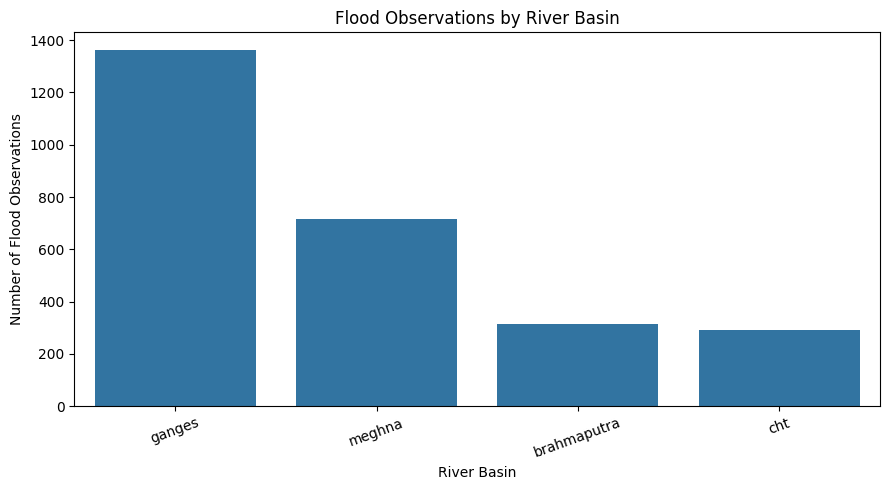

In [45]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=basin_floods,
    x="basin",
    y="flood_observations")

plt.title("Flood Observations by River Basin")
plt.xlabel("River Basin")
plt.ylabel("Number of Flood Observations")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### Comparing Monitoring Stations Within Basins

I summarized the number and percentage of positive flood labels for each station, allowing more detailed station-level comparisons.

In [46]:
station_floods = (
    df_clean.groupby(["basin", "station_name"])
    .agg(
        flood_count=("flood_within_24h", "sum"),
        observations=("flood_within_24h", "count"),
        flood_rate=("flood_within_24h", "mean")).reset_index())

station_floods["flood_rate"] *= 100

station_floods.sort_values("flood_rate", ascending=False)

,basin,station_name,flood_count,observations,flood_rate
12,ganges,Bagerhat,330.0,1826,18.072289
16,ganges,Gopalganj,230.0,1826,12.595838
19,ganges,Khulna (Rupsha),188.0,1826,10.295728
15,ganges,Goalanda (Jamuna-Ganges confluence),153.0,1826,8.378970
29,meghna,Sylhet,126.0,1826,6.900329
13,ganges,Barisal,123.0,1826,6.736035
20,ganges,Mawa,122.0,1826,6.681271
24,meghna,Chandpur (Padma-Meghna confluence),122.0,1826,6.681271
27,meghna,Sherpur (Sylhet),112.0,1826,6.133625
23,meghna,Bhairab Bazar,97.0,1826,5.312158


Flood Observations Across Monitoring Stations

The station-level analysis revealed substantial differences in recorded flood occurrence across the monitoring network.

Bagerhat had the highest flood observation rate (18.07%), followed by Gopalganj (12.60%) and Khulna (10.30%), all located within the Ganges basin. In contrast, stations in the Brahmaputra basin generally showed lower rates, ranging from approximately 1.42% to 2.90%.

The results also demonstrate that flood observation rates vary considerably within the same river basin. This suggests that basin-level comparisons alone may not capture local differences in flood patterns.

These findings support further investigation into the relationship between local hydrological conditions, rainfall patterns, soil moisture, and flood occurrence.

### Defining a Candidate Connected River Network

I selected SW17 (Chilmari), SW90 (Bahadurabad), SW93 (Sariakandi), and SW99 (Sirajganj) for further exploration of the Brahmaputra–Jamuna river system. The expected upstream/downstream relationships still require hydrological verification.

In [47]:
connected_stations = [
    "SW17",  # Chilmari
    "SW90",  # Bahadurabad
    "SW93",  # Sariakandi
    "SW99"   # Sirajganj
    ]

df_network = df_clean[
    df_clean["station_id"].isin(connected_stations)].copy()

### Counting Flood Labels at Candidate Stations

I compared the number of observed labels and positive flood cases among the selected stations.

In [48]:
df_network.groupby(
    ["station_id", "station_name"]).agg(
    observations=("flood_within_24h", "count"),
    floods=("flood_within_24h", "sum"))

,,observations,floods
station_id,station_name,,
SW17,Chilmari,1826,30.0
SW90,Bahadurabad,1826,53.0
SW93,Sariakandi,1826,51.0
SW99,Sirajganj,1826,35.0


### Checking Candidate Station Time Coverage

I identified the first and last dates and number of observed target records for each candidate station.

In [49]:
df_network.reset_index().groupby("station_name").agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    observations=("flood_within_24h", "count"))

,first_date,last_date,observations
station_name,,,
Bahadurabad,2021-01-01,2025-12-31,1826
Chilmari,2021-01-01,2025-12-31,1826
Sariakandi,2021-01-01,2025-12-31,1826
Sirajganj,2021-01-01,2025-12-31,1826


### Aligning Discharge Series Across Stations

I reshaped the data so each station has its own estimated river-discharge column and all series share a common date index.

In [50]:
df_network = df_network.reset_index()

discharge_comparison = df_network.pivot(
    index="date",
    columns="station_name",
    values="river_discharge_m3s")

discharge_comparison.head(10)

station_name,Bahadurabad,Chilmari,Sariakandi,Sirajganj
date,,,,
2021-01-01,3898.42,3705.81,4026.17,4054.09
2021-01-02,3836.07,3646.54,3961.78,3998.45
2021-01-03,3774.72,3588.22,3898.42,3934.50
2021-01-04,3714.35,3522.71,3818.44,3836.07
2021-01-05,3638.15,3466.37,3740.11,3748.73
2021-01-06,3579.96,3403.08,3671.82,3680.29
2021-01-07,3514.60,3348.66,3604.79,3613.10
2021-01-08,3466.37,3295.10,3547.13,3555.31
2021-01-09,3434.58,3264.88,3506.52,3506.52


### Calculating Discharge Correlations

I calculated pairwise correlations between the candidate station discharge series to understand how similarly they vary.

In [51]:
discharge_corr = discharge_comparison.corr()

discharge_corr

station_name,Bahadurabad,Chilmari,Sariakandi,Sirajganj
station_name,,,,
Bahadurabad,1.000000,0.999552,0.999607,0.999055
Chilmari,0.999552,1.000000,0.998608,0.997757
Sariakandi,0.999607,0.998608,1.000000,0.999877
Sirajganj,0.999055,0.997757,0.999877,1.000000


### Visualizing Discharge Correlations

I used a heatmap to compare discharge correlations among candidate stations. Strong correlations do not independently verify a physical routing connection or useful forecasting lead time.

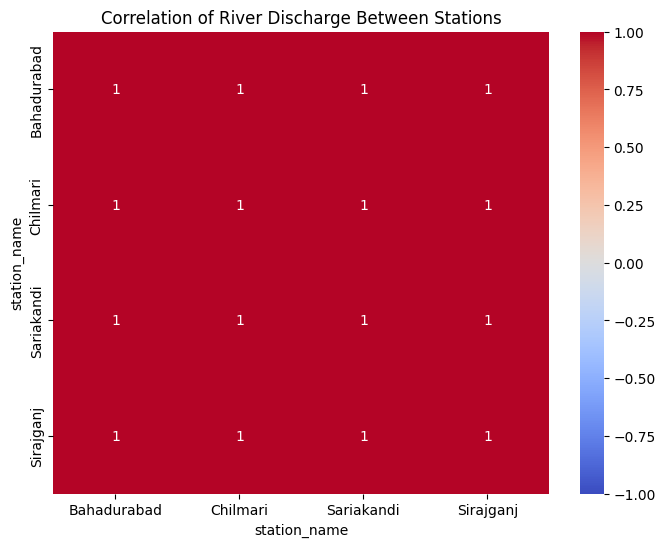

In [52]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    discharge_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1)

plt.title("Correlation of River Discharge Between Stations")
plt.show()

### Summarizing Station Discharge

I inspected the typical values and variability of estimated discharge at the candidate stations.

In [53]:
discharge_comparison.describe()

station_name,Bahadurabad,Chilmari,Sariakandi,Sirajganj
count,1826.000000,1826.000000,1826.000000,1826.000000
mean,19397.085356,18318.511676,19593.536681,19621.270027
std,17215.226063,16182.644091,17337.779311,17368.567062
min,2459.370000,2370.370000,2493.600000,2465.040000
25%,4527.970000,4235.430000,4580.420000,4561.997500
50%,13151.250000,12602.760000,13242.420000,13303.550000
75%,30689.220000,28939.152500,31169.960000,31187.890000
max,89948.760000,84332.500000,91200.090000,91621.020000


### Checking Correlation Precision

I displayed the discharge correlations with more decimal places for comparison.

In [54]:
discharge_comparison.corr().round(6)

station_name,Bahadurabad,Chilmari,Sariakandi,Sirajganj
station_name,,,,
Bahadurabad,1.000000,0.999552,0.999607,0.999055
Chilmari,0.999552,1.000000,0.998608,0.997757
Sariakandi,0.999607,0.998608,1.000000,0.999877
Sirajganj,0.999055,0.997757,0.999877,1.000000


### Correlations of Daily Discharge Changes

I calculated correlations of day-to-day discharge changes, which can reveal different relationships than correlations of raw levels.

In [55]:
discharge_diff = discharge_comparison.diff()

discharge_diff.corr().round(4)

station_name,Bahadurabad,Chilmari,Sariakandi,Sirajganj
station_name,,,,
Bahadurabad,1.0000,0.9912,0.9852,0.9643
Chilmari,0.9912,1.0000,0.9570,0.9262
Sariakandi,0.9852,0.9570,1.0000,0.9951
Sirajganj,0.9643,0.9262,0.9951,1.0000


### Finding Discharge-Related Features

I listed all columns with `discharge` in their names to inspect the available hydrological variables.

In [56]:
[col for col in df_clean.columns if "discharge" in col]

['river_discharge_m3s',
 'river_discharge_m3s_missing',
 'river_discharge_m3s_lag1d',
 'river_discharge_m3s_lag2d',
 'river_discharge_m3s_lag3d',
 'river_discharge_m3s_lag5d']

### Finding Upstream-Related Features

I listed upstream-related columns to see which potential predictors the dataset provides.

In [57]:
[col for col in df_clean.columns if "upstream" in col.lower()]

['rainfall_upstream_mm',
 'rainfall_upstream_mm_missing',
 'rainfall_upstream_mm_lag1d',
 'rainfall_upstream_mm_lag2d',
 'rainfall_upstream_mm_lag3d',
 'rainfall_upstream_mm_lag5d',
 'rainfall_upstream_mm_sum7d',
 'rainfall_upstream_mm_sum14d']

### Checking Which Upstream Features Remain

I compared selected upstream-discharge feature names against the cleaned columns to see which survived the earlier drop step.

In [58]:
upstream_features = [
    "upstream_chain_discharge_lag1d",
    "upstream_chain_discharge_lag2d",
    "upstream_reference_discharge_lag2d",
    "upstream_reference_discharge_lag3d"
]

[col for col in upstream_features if col in df_clean.columns]

[]

### Inspecting Original Upstream Variables

I viewed the original upstream discharge columns together with station and date identifiers, before further filtering.

In [59]:
df[[
    "station_id",
    "date",
    "upstream_chain_discharge_lag1d",
    "upstream_chain_discharge_lag2d",
    "upstream_reference_discharge_lag2d",
    "upstream_reference_discharge_lag3d"
]].head()

,station_id,date,upstream_chain_discharge_lag1d,upstream_chain_discharge_lag2d,upstream_reference_discharge_lag2d,upstream_reference_discharge_lag3d
0,CH01,1950-01-01,NaN,NaN,NaN,NaN
1,CH01,1950-01-02,NaN,NaN,NaN,NaN
2,CH01,1950-01-03,NaN,NaN,NaN,NaN
3,CH01,1950-01-04,NaN,NaN,NaN,NaN
4,CH01,1950-01-05,NaN,NaN,NaN,NaN


### Checking Upstream Feature Availability by Station

I summarized the count, mean, and variability of upstream discharge features for the selected stations in the exploratory window.

In [60]:
connected_stations = ["SW17", "SW90", "SW93", "SW99"]

upstream_features = [
    "upstream_chain_discharge_lag1d",
    "upstream_chain_discharge_lag2d",
    "upstream_reference_discharge_lag2d",
    "upstream_reference_discharge_lag3d"
]

df_upstream_check = df[
    (df["station_id"].isin(connected_stations)) &
    (df["date"] >= "2021-01-01") &
    (df["date"] <= "2025-12-31")
].copy()

df_upstream_check.groupby("station_id")[upstream_features].agg(
    ["count", "mean", "std"]
)

upstream_chain_discharge_lag1d                              \
                                    count          mean           std   
station_id                                                              
SW17                                    0           NaN           NaN   
SW90                                 1826  18318.976961  16182.213215   
SW93                                 1826  19397.592892  17214.756802   
SW99                                 1826  19594.062048  17337.294759   

           upstream_chain_discharge_lag2d           \
                                    count mean std   
station_id                                           
SW17                                    0  NaN NaN   
SW90                                    0  NaN NaN   
SW93                                    0  NaN NaN   
SW99                                    0  NaN NaN   

           upstream_reference_discharge_lag2d           \
                                        count mean std   
station_id                                               
SW17                                        0  NaN NaN   
SW90                                        0  NaN NaN   
SW93                                        0  NaN NaN   
SW99                                        0  NaN NaN   

           upstream_reference_discharge_lag3d           
                                        count mean std  
station_id                                              
SW17                                        0  NaN NaN  
SW90                                        0  NaN NaN  
SW93                                        0  NaN NaN  
SW99                                        0  NaN NaN

### Merging an Original Upstream Variable

I attempted to restore `upstream_chain_discharge_lag1d` from the original dataset by station and date. **Execution note:** earlier cells set `date` as an index, so this merge may depend on the current DataFrame structure; also check that the merged column is not already present. I have left the original code unchanged.

In [61]:
# Original upstream feature
upstream_data = df[
    ["station_id", "date", "upstream_chain_discharge_lag1d"]].copy()

# Keep only our connected stations and period
upstream_data = upstream_data[
    upstream_data["station_id"].isin(connected_stations) &
    (upstream_data["date"] >= "2021-01-01") &
    (upstream_data["date"] <= "2025-12-31")]

# Merge the upstream feature
df_clean = df_clean.merge(
    upstream_data,
    on=["station_id", "date"],
    how="left",
    validate="one_to_one")

### Summarizing Available Upstream Discharge

I inspected non-null counts and basic statistics of the upstream discharge feature by station.

In [62]:
df_clean.groupby("station_id")[
    "upstream_chain_discharge_lag1d"].agg(["count", "mean", "std"])

,count,mean,std
station_id,,,
CH01,0,NaN,NaN
CH02,0,NaN,NaN
CH03,0,NaN,NaN
CO01,0,NaN,NaN
CO02,0,NaN,NaN
CO03,0,NaN,NaN
CO04,0,NaN,NaN
CO05,0,NaN,NaN
DH01,0,NaN,NaN


### Inspecting SW99 Discharge and Labels

I viewed sample SW99 records to compare local discharge, its upstream feature, and the flood target.

In [63]:
df_clean.loc[df_clean["station_id"] == "SW99",[
        "date",
        "river_discharge_m3s",
        "upstream_chain_discharge_lag1d",
        "flood_within_24h"]].head(15)

,date,river_discharge_m3s,upstream_chain_discharge_lag1d,flood_within_24h
27,2021-01-01,4054.09,4091.61,0.0
57,2021-01-02,3998.45,4026.17,0.0
87,2021-01-03,3934.50,3961.78,0.0
117,2021-01-04,3836.07,3898.42,0.0
147,2021-01-05,3748.73,3818.44,0.0
177,2021-01-06,3680.29,3740.11,0.0
207,2021-01-07,3613.10,3671.82,0.0
237,2021-01-08,3555.31,3604.79,0.0
267,2021-01-09,3506.52,3547.13,0.0
297,2021-01-10,3474.36,3506.52,0.0


### Comparing Local and Upstream SW99 Discharge

I calculated the correlation between SW99 local discharge and its available upstream discharge feature.

In [64]:
sw99 = df_clean[df_clean["station_id"] == "SW99"].copy()

sw99[[
    "river_discharge_m3s",
    "upstream_chain_discharge_lag1d"]].corr()

,river_discharge_m3s,upstream_chain_discharge_lag1d
river_discharge_m3s,1.000000,0.993702
upstream_chain_discharge_lag1d,0.993702,1.000000


### Extracting the SW99 Time Series

I isolated historical records for SW99 and sorted the station data chronologically for an individual-station quality assessment.

In [65]:
sw99_2000 = df[
    (df["station_id"] == "SW99") &
    (df["date"] >= "2000-01-01") &
    (df["date"] <= "2025-12-31")].copy()

sw99_2000 = sw99_2000.sort_values("date")

### Inspecting SW99 Records and Target Coverage

I checked SW99 record counts, date range, and how often the flood target is known or missing.

In [66]:
print("Shape:", sw99_2000.shape)

print("First date:", sw99_2000["date"].min())
print("Last date:", sw99_2000["date"].max())

print("\nFlood labels:")
print(sw99_2000["flood_within_24h"].value_counts(dropna=False))

print("\nAvailable data:")
print(sw99_2000[
    [
        "river_discharge_m3s",
        "upstream_chain_discharge_lag1d",
        "flood_within_24h"]].notna().sum())

Shape: (9497, 50)
First date: 2000-01-01 00:00:00
Last date: 2025-12-31 00:00:00

Flood labels:
flood_within_24h
NaN    6239
0.0    2930
1.0     328
Name: count, dtype: int64

Available data:
river_discharge_m3s               9497
upstream_chain_discharge_lag1d    9497
flood_within_24h                  3258
dtype: int64


### Summarizing SW99 Labels by Year

I grouped SW99 by year to identify how many usable labels and positive cases occur in different periods.

In [67]:
sw99_2000["year"] = pd.to_datetime(
    sw99_2000["date"]).dt.year

yearly_floods = sw99_2000.groupby("year").agg(
    observations=("flood_within_24h", "count"),
    floods=("flood_within_24h", "sum"))

print(yearly_floods)

      observations  floods
year                      
2000             0     0.0
2001             0     0.0
2002             0     0.0
2003           122   122.0
2004             0     0.0
2005            20    20.0
2006             0     0.0
2007           101   101.0
2008             0     0.0
2009             0     0.0
2010             0     0.0
2011             0     0.0
2012             1     0.0
2013           365     7.0
2014           365    15.0
2015           365    26.0
2016            90     0.0
2017             0     0.0
2018             0     0.0
2019             1     1.0
2020             2     1.0
2021           365     6.0
2022           365    12.0
2023           365    12.0
2024           366     4.0
2025           365     1.0


### Confirming the SW99 Station Name

I checked the distinct station metadata attached to the selected identifier.

In [68]:
sw99_2000[["station_id", "station_name"]].drop_duplicates()

,station_id,station_name
773668,SW99,Sirajganj


### Inspecting SW99 Label Regimes

I counted the target label-regime categories to distinguish observed labels from other cases.

In [69]:
sw99_2000["flood_within_24h_label_regime"].value_counts(
    dropna=False)

,count
flood_within_24h_label_regime,
None,6239
observed,3013
unobserved_positive,245


### SW99 Label Regimes Over Time

I cross-tabulated year and label regime to see when observed target labels are available.

In [70]:
pd.crosstab(
    sw99_2000["year"],
    sw99_2000["flood_within_24h_label_regime"])

flood_within_24h_label_regime,observed,unobserved_positive
year,,
2003,0,122
2005,0,20
2007,0,101
2012,1,0
2013,365,0
2014,365,0
2015,365,0
2016,90,0
2019,0,1


### Keeping SW99 Observed Labels

I selected SW99 rows with observed labels and examined their class balance and yearly distribution.

In [71]:
sw99_observed = sw99_2000[
    sw99_2000["flood_within_24h_label_regime"] == "observed"].copy()

print("Shape:", sw99_observed.shape)

print(
    sw99_observed["flood_within_24h"]
    .value_counts())

print(
    sw99_observed.groupby("year")["flood_within_24h"]
    .agg(["count", "sum", "mean"]))

Shape: (3013, 50)
flood_within_24h
0.0    2930
1.0      83
Name: count, dtype: int64
      count   sum      mean
year                       
2012      1   0.0  0.000000
2013    365   7.0  0.019178
2014    365  15.0  0.041096
2015    365  26.0  0.071233
2016     90   0.0  0.000000
2020      1   0.0  0.000000
2021    365   6.0  0.016438
2022    365  12.0  0.032877
2023    365  12.0  0.032877
2024    366   4.0  0.010929
2025    365   1.0  0.002740


### Missing Values in SW99 Observed Records

I inspected which columns have the most missing values in the labeled SW99 sample.

In [72]:
sw99_observed.isna().sum().sort_values(
    ascending=False).head(20)

,0
upstream_chain_discharge_lag2d,3013
upstream_reference_discharge_lag2d,3013
upstream_reference_discharge_lag3d,3013
flood_byStor,2930
rainfall_local_mm_trend_ratio,745
rainfall_upstream_mm_trend_ratio,13
flood_within_72h,2
flood_within_72h_label_regime,2
flood_within_48h_label_regime,1
flood_within_48h,1


### SW99 Upstream Feature Completeness

I counted missing values in upstream-related columns for SW99.

In [73]:
upstream_cols = [
    col for col in sw99_observed.columns
    if "upstream" in col.lower()]

sw99_observed[upstream_cols].isna().sum()

,0
rainfall_upstream_mm,0
rainfall_upstream_mm_missing,0
rainfall_upstream_mm_lag1d,0
rainfall_upstream_mm_lag2d,0
rainfall_upstream_mm_lag3d,0
rainfall_upstream_mm_lag5d,0
rainfall_upstream_mm_sum7d,0
rainfall_upstream_mm_sum14d,0
rainfall_upstream_mm_trend_ratio,13
upstream_chain_discharge_lag1d,0


### SW99 Local Feature Completeness

I examined missing values for rainfall, soil moisture, and discharge features at SW99.

In [74]:
local_cols = [
    col for col in sw99_observed.columns
    if any(x in col.lower() for x in [
        "rainfall_local",
        "soil_moisture",
        "river_discharge"])]

sw99_observed[local_cols].isna().sum().sort_values(
    ascending=False)

,0
rainfall_local_mm_trend_ratio,745
soil_moisture_local,0
rainfall_local_mm,0
rainfall_local_mm_missing,0
soil_moisture_local_missing,0
river_discharge_m3s_missing,0
river_discharge_m3s,0
rainfall_local_mm_lag1d,0
rainfall_local_mm_lag2d,0
rainfall_local_mm_lag5d,0


### SW99 Duplicate and Target Checks

I checked repeated dates and rows, along with the target distribution, before deciding whether SW99 could support modeling.

In [75]:
print("Duplicate dates:",
      sw99_observed["date"].duplicated().sum())

print("Duplicate rows:",
      sw99_observed.duplicated().sum())

print("Target distribution:")
print(sw99_observed["flood_within_24h"].value_counts())

print("Date range:")
print(sw99_observed["date"].min(),
      sw99_observed["date"].max())

Duplicate dates: 0
Duplicate rows: 0
Target distribution:
flood_within_24h
0.0    2930
1.0      83
Name: count, dtype: int64
Date range:
2012-12-31 00:00:00 2025-12-31 00:00:00


### Creating a Candidate Local Feature List

I assembled local rainfall, soil-moisture, and estimated-discharge features, including lagged and rolling summaries, for a possible local-only model.

In [76]:
local_features = [
    "rainfall_local_mm",
    "soil_moisture_local",
    "river_discharge_m3s",
    "rainfall_local_mm_lag1d",
    "rainfall_local_mm_lag2d",
    "rainfall_local_mm_lag3d",
    "rainfall_local_mm_lag5d",
    "rainfall_local_mm_sum7d",
    "rainfall_local_mm_sum14d",
    "soil_moisture_local_lag1d",
    "soil_moisture_local_lag2d",
    "soil_moisture_local_lag3d",
    "soil_moisture_local_lag5d",
    "soil_moisture_delta_30d",
    "soil_moisture_swi",
    "river_discharge_m3s_lag1d",
    "river_discharge_m3s_lag2d",
    "river_discharge_m3s_lag3d",
    "river_discharge_m3s_lag5d"]

### Creating a Candidate Upstream Feature List

I assembled upstream rainfall and lagged discharge features to test whether upstream information improves predictions compared with local information alone.

In [77]:
upstream_features = [
    "rainfall_upstream_mm",
    "rainfall_upstream_mm_lag1d",
    "rainfall_upstream_mm_lag2d",
    "rainfall_upstream_mm_lag3d",
    "rainfall_upstream_mm_lag5d",
    "rainfall_upstream_mm_sum7d",
    "rainfall_upstream_mm_sum14d",
    "upstream_chain_discharge_lag1d"]

### Checking Feature Names

I checked whether the candidate local and upstream features actually exist in the observed-label station data.

In [78]:
missing_features = [
    col for col in local_features + upstream_features
    if col not in sw99_observed.columns]

print("Missing columns:", missing_features)

Missing columns: []


### Reviewing SW99 Observed Cases by Year

I counted the observed labels and positive flood cases for each year to identify better-supported periods.

In [79]:
print(
    sw99_observed.groupby("year")["flood_within_24h"]
    .agg(["count", "sum"]))

      count   sum
year             
2012      1   0.0
2013    365   7.0
2014    365  15.0
2015    365  26.0
2016     90   0.0
2020      1   0.0
2021    365   6.0
2022    365  12.0
2023    365  12.0
2024    366   4.0
2025    365   1.0


### Extracting the SW90 Time Series

I isolated historical data for SW90 (Bahadurabad) and sorted it by date to compare it with SW99.

In [80]:
sw90_2000 = df[
    (df["station_id"] == "SW90") &
    (df["date"] >= "2000-01-01") &
    (df["date"] <= "2025-12-31")].copy()

sw90_2000 = sw90_2000.sort_values("date")

### Inspecting SW90 Records and Target Coverage

I checked the number of records, date range, target-label counts, and station coverage at SW90.

In [81]:
print("Shape:", sw90_2000.shape)

print("First date:", sw90_2000["date"].min())
print("Last date:", sw90_2000["date"].max())

print("\nFlood labels:")
print(sw90_2000["flood_within_24h"].value_counts(dropna=False))

print("\nStation:")
print(sw90_2000[["station_id", "station_name"]].drop_duplicates())

Shape: (9497, 50)
First date: 2000-01-01 00:00:00
Last date: 2025-12-31 00:00:00

Flood labels:
flood_within_24h
NaN    6186
0.0    2887
1.0     424
Name: count, dtype: int64

Station:
       station_id station_name
717712       SW90  Bahadurabad


### Summarizing SW90 Flood Labels by Year

I examined the yearly distribution of known labels and positive flood cases at SW90.

In [82]:
sw90_2000["year"] = pd.to_datetime(
    sw90_2000["date"]).dt.year

yearly_floods_sw90 = sw90_2000.groupby("year").agg(
    observations=("flood_within_24h", "count"),
    floods=("flood_within_24h", "sum"))

print(yearly_floods_sw90)

      observations  floods
year                      
2000             0     0.0
2001             0     0.0
2002             0     0.0
2003           122   122.0
2004             0     0.0
2005            20    20.0
2006             0     0.0
2007           101   101.0
2008            10    10.0
2009             0     0.0
2010             0     0.0
2011             0     0.0
2012            25    24.0
2013           365    10.0
2014           365    30.0
2015           365    33.0
2016            91     1.0
2017            17    17.0
2018             1     1.0
2019             2     2.0
2020             1     0.0
2021           365    13.0
2022           365    19.0
2023           365    11.0
2024           366     7.0
2025           365     3.0


### Checking SW90 Label-Regime Coverage

I compared target label regimes and their yearly occurrence to identify periods with reliable observed labels.

In [83]:
print(
    sw90_2000["flood_within_24h_label_regime"]
    .value_counts(dropna=False))

print(
    pd.crosstab(
        sw90_2000["year"],
        sw90_2000["flood_within_24h_label_regime"]))

flood_within_24h_label_regime
None                   6186
observed               3013
unobserved_positive     298
Name: count, dtype: int64
flood_within_24h_label_regime  observed  unobserved_positive
year                                                        
2003                                  0                  122
2005                                  0                   20
2007                                  0                  101
2008                                  0                   10
2012                                  1                   24
2013                                365                    0
2014                                365                    0
2015                                365                    0
2016                                 90                    1
2017                                  0                   17
2018                                  0                    1
2019                                  0                    2
2020  

### Selecting Observed SW90 Labels

I kept SW90 records marked as `observed` and reviewed the resulting class balance and yearly positive-case counts.

In [84]:
sw90_observed = sw90_2000[
    sw90_2000["flood_within_24h_label_regime"] == "observed"].copy()

print("Shape:", sw90_observed.shape)

print(sw90_observed["flood_within_24h"].value_counts())

print(sw90_observed.groupby("year")["flood_within_24h"].agg(["count", "sum", "mean"]))

Shape: (3013, 50)
flood_within_24h
0.0    2887
1.0     126
Name: count, dtype: int64
      count   sum      mean
year                       
2012      1   0.0  0.000000
2013    365  10.0  0.027397
2014    365  30.0  0.082192
2015    365  33.0  0.090411
2016     90   0.0  0.000000
2020      1   0.0  0.000000
2021    365  13.0  0.035616
2022    365  19.0  0.052055
2023    365  11.0  0.030137
2024    366   7.0  0.019126
2025    365   3.0  0.008219


### Checking Missing Values at SW90

I identified columns with the most missing values in the observed SW90 sample.

In [85]:
sw90_observed.isna().sum().sort_values(
    ascending=False).head(20)

,0
upstream_chain_discharge_lag2d,3013
upstream_reference_discharge_lag2d,3013
upstream_reference_discharge_lag3d,3013
flood_byStor,2914
rainfall_local_mm_trend_ratio,727
rainfall_upstream_mm_trend_ratio,13
flood_within_72h,2
flood_within_72h_label_regime,2
flood_within_48h_label_regime,1
flood_within_48h,1


### Checking SW90 Upstream Data

I inspected missing values specifically in upstream-related columns for the SW90 modeling candidate.

In [86]:
upstream_cols = [
    col for col in sw90_observed.columns
    if "upstream" in col.lower()]

sw90_observed[upstream_cols].isna().sum()

,0
rainfall_upstream_mm,0
rainfall_upstream_mm_missing,0
rainfall_upstream_mm_lag1d,0
rainfall_upstream_mm_lag2d,0
rainfall_upstream_mm_lag3d,0
rainfall_upstream_mm_lag5d,0
rainfall_upstream_mm_sum7d,0
rainfall_upstream_mm_sum14d,0
rainfall_upstream_mm_trend_ratio,13
upstream_chain_discharge_lag1d,0


### Checking SW90 Local Data

I checked whether local rainfall, soil-moisture, and discharge features are populated at SW90.

In [87]:
local_cols = [
    col for col in sw90_observed.columns
    if any(x in col.lower() for x in [
        "rainfall_local",
        "soil_moisture",
        "river_discharge"])]

sw90_observed[local_cols].isna().sum().sort_values(
    ascending=False)

,0
rainfall_local_mm_trend_ratio,727
soil_moisture_local,0
rainfall_local_mm,0
rainfall_local_mm_missing,0
soil_moisture_local_missing,0
river_discharge_m3s_missing,0
river_discharge_m3s,0
rainfall_local_mm_lag1d,0
rainfall_local_mm_lag2d,0
rainfall_local_mm_lag5d,0


### Verifying Daily Date Continuity

I examined differences between consecutive SW90 dates to see whether the full station time series contains gaps.

In [88]:
# Check whether SW90 has consecutive daily dates

dates = (
    sw90_2000["date"]
    .drop_duplicates()
    .sort_values())

date_gaps = dates.diff().value_counts()

print("Date differences:")
print(date_gaps.head(10))

print("\nNumber of gaps larger than 1 day:")
print((dates.diff() > pd.Timedelta(days=1)).sum())

print("\nLargest date gap:")
print(dates.diff().max())

Date differences:
date
1 days    9496
Name: count, dtype: int64

Number of gaps larger than 1 day:
0

Largest date gap:
1 days 00:00:00


### Checking SW90 Positive Cases by Year

I summarized known daily labels and flood-positive cases by year in the observed SW90 subset.

In [89]:
sw90_observed.groupby(
    sw90_observed["date"].dt.year
)["flood_within_24h"].agg(["count", "sum"])

,count,sum
date,,
2012,1,0.0
2013,365,10.0
2014,365,30.0
2015,365,33.0
2016,90,0.0
2020,1,0.0
2021,365,13.0
2022,365,19.0
2023,365,11.0


### Exporting an SW90 Candidate Dataset

I saved the observed SW90 records to a CSV file for possible later modeling. Exporting the file does not commit the project to this station or a final modeling setup.

In [90]:
# Save only SW90 observed data
sw90_observed.to_csv(
    "SW90_Bahadurabad.csv",
    index=False)

### Reviewing the Full SW90 Historical Series

I returned to the complete SW90 station data, including dates without observed target labels, to evaluate long-term coverage.

In [91]:
sw90 = df[df["station_id"] == "SW90"].copy()

sw90["date"] = pd.to_datetime(sw90["date"])

print("SW90 shape:", sw90.shape)

print("\nDate range:")
print("First date:", sw90["date"].min())
print("Last date:", sw90["date"].max())

SW90 shape: (27978, 50)

Date range:
First date: 1950-01-01 00:00:00
Last date: 2026-08-07 00:00:00


### Comparing SW90 Label Availability Across Years

I calculated total records, observed/known target labels, positive and negative cases, and flood-label rates by year. Years with only positive labels or very few labels must be interpreted cautiously, rather than treated as representative flood frequencies.

In [92]:
sw90["year"] = sw90["date"].dt.year

yearly_stats = sw90.groupby("year").agg(
    total_rows=("date", "count"),
    observed_labels=("flood_within_24h", "count"),
    flood_cases=("flood_within_24h", "sum")
)

yearly_stats["no_flood_cases"] = (
    yearly_stats["observed_labels"] - yearly_stats["flood_cases"]
)

yearly_stats["flood_rate_%"] = (
    yearly_stats["flood_cases"] /
    yearly_stats["observed_labels"] * 100
)

print(yearly_stats.to_string())

      total_rows  observed_labels  flood_cases  no_flood_cases  flood_rate_%
year                                                                        
1950         365                0          0.0             0.0           NaN
1951         365                0          0.0             0.0           NaN
1952         366                0          0.0             0.0           NaN
1953         365                0          0.0             0.0           NaN
1954         365                0          0.0             0.0           NaN
1955         365                0          0.0             0.0           NaN
1956         366                0          0.0             0.0           NaN
1957         365                0          0.0             0.0           NaN
1958         365                0          0.0             0.0           NaN
1959         365                0          0.0             0.0           NaN
1960         366                0          0.0             0.0           NaN

## Additional visualizations for choosing a basin and connected monitoring stations

The following charts use the **full original DataFrame (`df`)** rather than the temporary `df_clean` subset. Only target values explicitly marked `observed` are used to compare known flood and non-flood labels. These figures help shortlist a station and river system; they do not establish the final modeling period or prove the direction of water flow.

### 1. Basin comparison: positive cases and label coverage

I compare observed positive flood labels with the number of observed target records per basin. This helps distinguish a high count of positives from a basin that simply has more labeled observations. Basin labels follow the manually defined mapping above.

,observed_days,positive_labels,stations,positive_rate_pct
basin,,,,
ganges,30450,2119.0,10,6.96
meghna,24360,1391.0,8,5.71
brahmaputra,24360,776.0,8,3.19
cht,12180,560.0,4,4.60


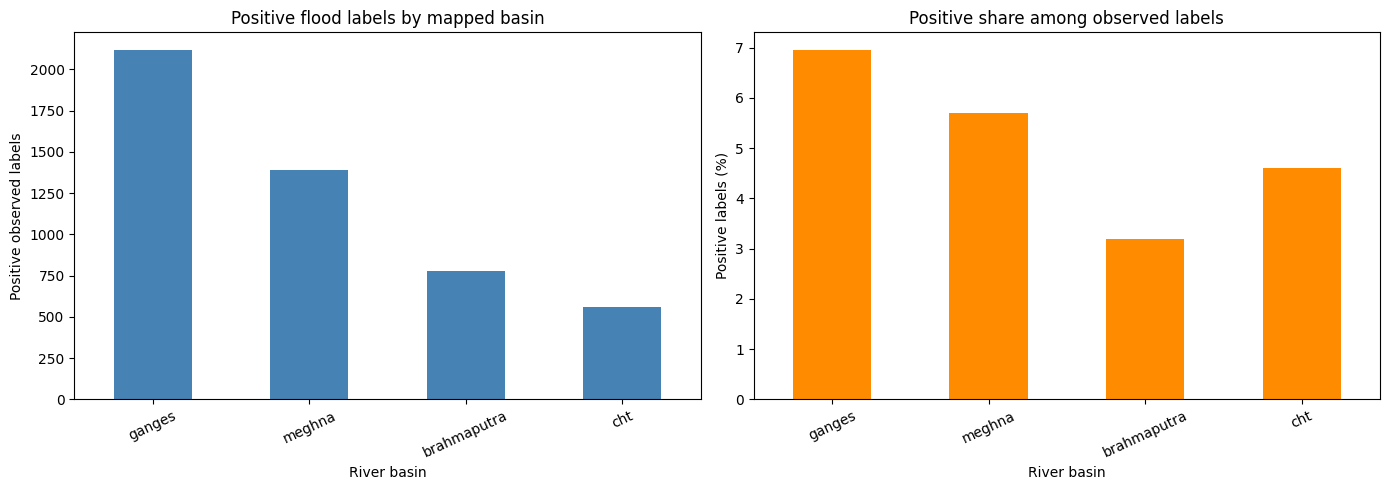

In [93]:
# Full-history observed labels; not restricted to the earlier exploratory subset
observed_all = df.loc[df["flood_within_24h_label_regime"].eq("observed")].copy()
observed_all["basin"] = observed_all["station_id"].map(basin_mapping)

basin_summary_full = (
    observed_all.dropna(subset=["basin", "flood_within_24h"])
    .groupby("basin")
    .agg(observed_days=("flood_within_24h", "size"),
         positive_labels=("flood_within_24h", "sum"),
         stations=("station_id", "nunique"))
    .sort_values("positive_labels", ascending=False)
)
basin_summary_full["positive_rate_pct"] = 100 * basin_summary_full["positive_labels"] / basin_summary_full["observed_days"]
display(basin_summary_full.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
basin_summary_full["positive_labels"].plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Positive flood labels by mapped basin", xlabel="River basin", ylabel="Positive observed labels")
basin_summary_full["positive_rate_pct"].plot.bar(ax=axes[1], color="darkorange")
axes[1].set(title="Positive share among observed labels", xlabel="River basin", ylabel="Positive labels (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### 2. Candidate network: observed labels and positive cases

I compare SW17, SW90, SW93, and SW99 using the same full-history observed-label definition. A station with both positive and negative examples and sufficient coverage is more useful for evaluating a binary classifier than one with isolated positive reports only.

,station_id,station_name,observed_days,positive_labels,negative_labels,positive_rate_pct
0,SW17,Chilmari,3045,100.0,2945.0,3.28
1,SW90,Bahadurabad,3045,126.0,2919.0,4.14
2,SW93,Sariakandi,3045,123.0,2922.0,4.04
3,SW99,Sirajganj,3045,83.0,2962.0,2.73


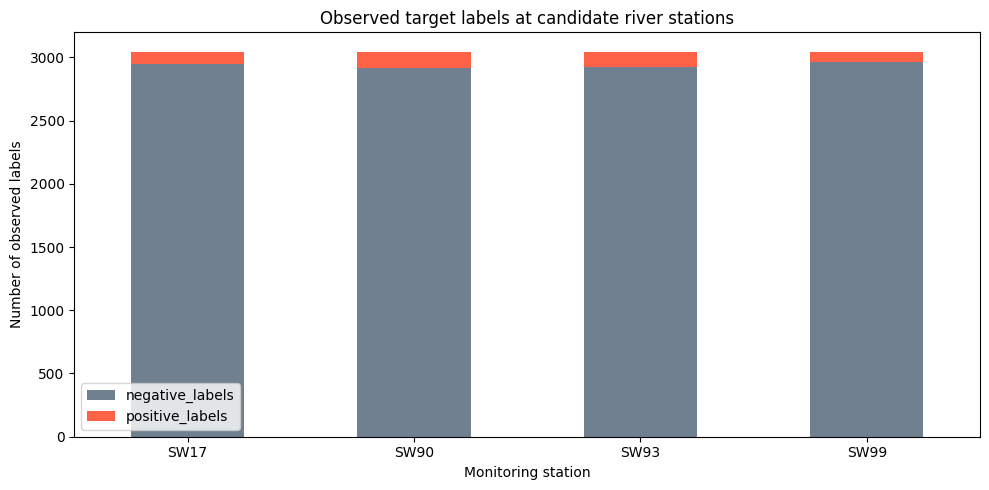

In [94]:
network_ids = ["SW17", "SW90", "SW93", "SW99"]
network_labels = observed_all[observed_all["station_id"].isin(network_ids)].copy()
station_summary_full = (
    network_labels.groupby(["station_id", "station_name"])["flood_within_24h"]
    .agg(observed_days="count", positive_labels="sum")
    .reset_index()
)
station_summary_full["negative_labels"] = station_summary_full["observed_days"] - station_summary_full["positive_labels"]
station_summary_full["positive_rate_pct"] = 100 * station_summary_full["positive_labels"] / station_summary_full["observed_days"]
display(station_summary_full.round(2))

if not station_summary_full.empty:
    plot_data = station_summary_full.set_index("station_id")[["negative_labels", "positive_labels"]]
    ax = plot_data.plot(kind="bar", stacked=True, figsize=(10, 5), color=["slategray", "tomato"])
    ax.set(title="Observed target labels at candidate river stations", xlabel="Monitoring station", ylabel="Number of observed labels")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### 3. SW90: where are the usable labels over time?

I compare the total number of daily records at SW90 with the observed target labels, and display positive labels separately. This makes years with sparse or positive-only labels visible. **Missing labels are not non-flood cases.**

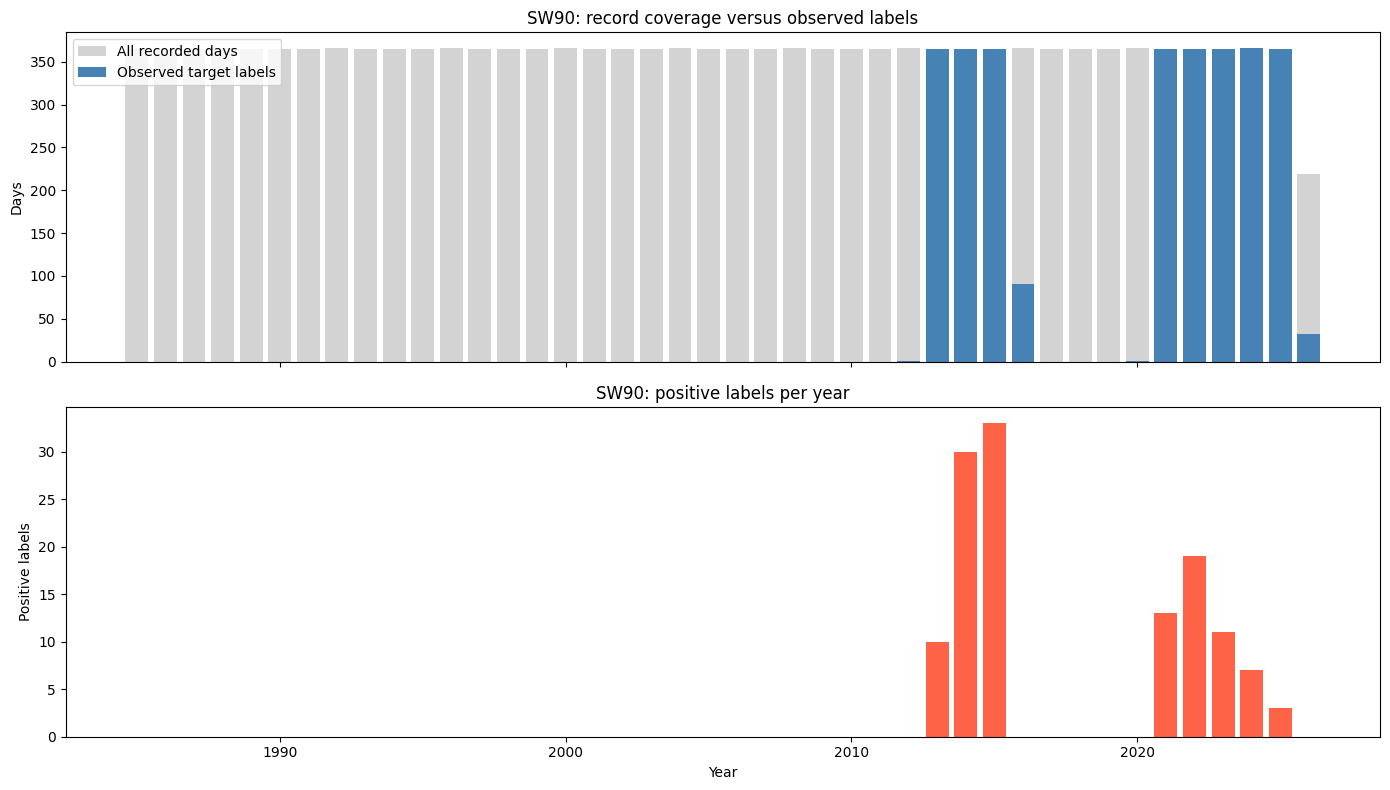

In [95]:
sw90_full = df.loc[df["station_id"].eq("SW90")].copy()
sw90_full["date"] = pd.to_datetime(sw90_full["date"])
sw90_full["year"] = sw90_full["date"].dt.year
sw90_labelled = sw90_full[sw90_full["flood_within_24h_label_regime"].eq("observed")]

all_days_sw90 = sw90_full.groupby("year").size().rename("total_days")
label_days_sw90 = sw90_labelled.groupby("year")["flood_within_24h"].agg(
    observed_days="count", positive_labels="sum")
sw90_coverage = all_days_sw90.to_frame().join(label_days_sw90, how="left").fillna(0)
sw90_coverage = sw90_coverage.loc[sw90_coverage.index >= 1985]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].bar(sw90_coverage.index, sw90_coverage["total_days"], label="All recorded days", color="lightgray")
axes[0].bar(sw90_coverage.index, sw90_coverage["observed_days"], label="Observed target labels", color="steelblue")
axes[0].set(ylabel="Days", title="SW90: record coverage versus observed labels")
axes[0].legend()
axes[1].bar(sw90_coverage.index, sw90_coverage["positive_labels"], color="tomato")
axes[1].set(xlabel="Year", ylabel="Positive labels", title="SW90: positive labels per year")
plt.tight_layout()
plt.show()

### 4. SW17 and SW90: comparing estimated discharge over time

I compare the estimated discharge time series for upstream candidate SW17 and target candidate SW90 during one illustrative year with complete matching dates. I normalize each series to reveal changes in timing rather than comparing absolute discharge magnitudes. Similar patterns are **not proof of hydrological travel time**; that would need further validation before adding an upstream predictor.

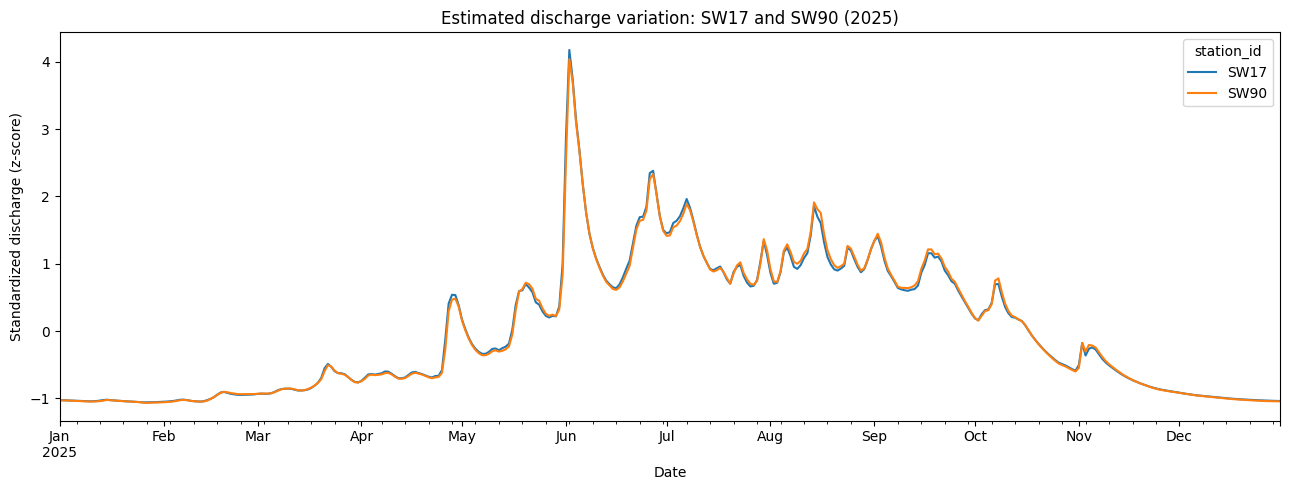

In [96]:
pair = df[df["station_id"].isin(["SW17", "SW90"])][["date", "station_id", "river_discharge_m3s"]].copy()
pair["date"] = pd.to_datetime(pair["date"])
pair_pivot = pair.pivot_table(index="date", columns="station_id", values="river_discharge_m3s", aggfunc="mean")

# Select the latest complete calendar year with enough paired data for a readable plot.
paired = pair_pivot[["SW17", "SW90"]].dropna() if {"SW17", "SW90"}.issubset(pair_pivot.columns) else pd.DataFrame()
if paired.empty:
    print("No paired discharge observations available for SW17 and SW90.")
else:
    year_counts = paired.groupby(paired.index.year).size()
    eligible_years = year_counts[year_counts >= 300]
    if eligible_years.empty:
        print("Not enough paired observations in any one year for this visualization.")
    else:
        example_year = int(eligible_years.index.max())
        selected = paired[paired.index.year == example_year]
        normalized = (selected - selected.mean()) / selected.std().replace(0, np.nan)
        ax = normalized.plot(figsize=(13, 5), linewidth=1.5)
        ax.set(title=f"Estimated discharge variation: SW17 and SW90 ({example_year})",
               xlabel="Date", ylabel="Standardized discharge (z-score)")
        plt.tight_layout()
        plt.show()

**Seasonal Analysis of Flood Occurrence – SW90 Bahadurabad**

In this analysis, I examine the monthly distribution of flood-labeled days at SW90 – Bahadurabad on the Jamuna River.

The objective is to identify seasonal patterns and determine which months have the highest number of observed flood labels.

Since historical flood-label coverage is incomplete, I compare both the number of flood-labeled days and the percentage of positive labels among observed days.

,observed_days,flood_days,flood_rate
Jan,310,0.0,0.000000
Feb,255,1.0,0.392157
Mar,278,1.0,0.359712
Apr,240,2.0,0.833333
May,248,9.0,3.629032
Jun,240,27.0,11.250000
Jul,248,17.0,6.854839
Aug,248,36.0,14.516129
Sep,240,31.0,12.916667
Oct,248,2.0,0.806452


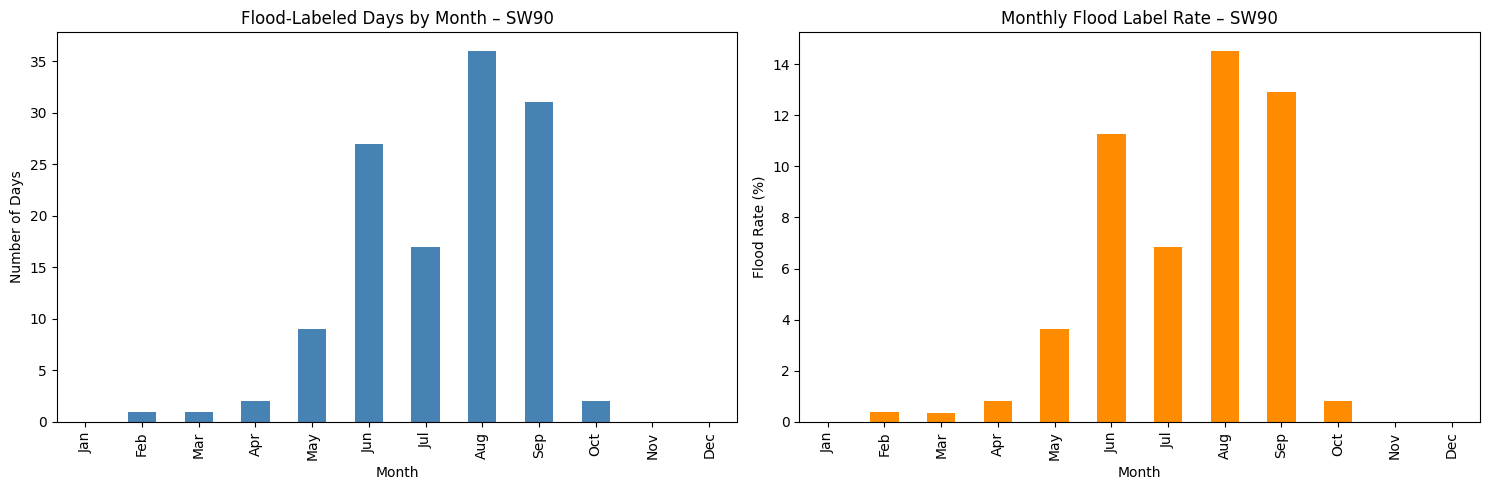

In [97]:
sw90_seasonal = sw90[
    (sw90["flood_within_24h_label_regime"] == "observed") &
    (sw90["flood_within_24h"].isin([0, 1]))].copy()

sw90_seasonal["month"] = sw90_seasonal["date"].dt.month

monthly_floods = sw90_seasonal.groupby("month").agg(
    observed_days=("flood_within_24h", "count"),
    flood_days=("flood_within_24h", "sum")).reindex(range(1, 13), fill_value=0)

monthly_floods["flood_rate"] = (
    monthly_floods["flood_days"] /
    monthly_floods["observed_days"].replace(0, float("nan")) * 100)

monthly_floods.index = [calendar.month_abbr[i] for i in range(1, 13)]

display(monthly_floods)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

monthly_floods["flood_days"].plot(
    kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Flood-Labeled Days by Month – SW90")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Days")

monthly_floods["flood_rate"].plot(
    kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Monthly Flood Label Rate – SW90")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Flood Rate (%)")

plt.tight_layout()
plt.show()

The analysis reveals a clear seasonal pattern in flood-labeled days at SW90 – Bahadurabad.

The highest numbers of positive flood labels were recorded in August (36 days), September (31 days), and June (27 days). The monthly flood-label rate was also highest in these months.

These results suggest that flood occurrence is strongly concentrated during the summer monsoon season, particularly between June and September.

However, historical flood-label coverage is incomplete, so the findings should be interpreted as patterns in the available labeled data rather than exact historical flood probabilities.

,avg_rainfall,avg_discharge
Jan,0.387851,3409.463946
Feb,0.588506,3610.746293
Mar,1.654881,6235.551828
Apr,5.773160,12848.548733
May,12.369501,20253.030151
Jun,13.982944,39818.741422
Jul,11.423377,54149.748839
Aug,9.100635,42120.374436
Sep,7.874518,33950.398023
Oct,4.307385,20743.428765


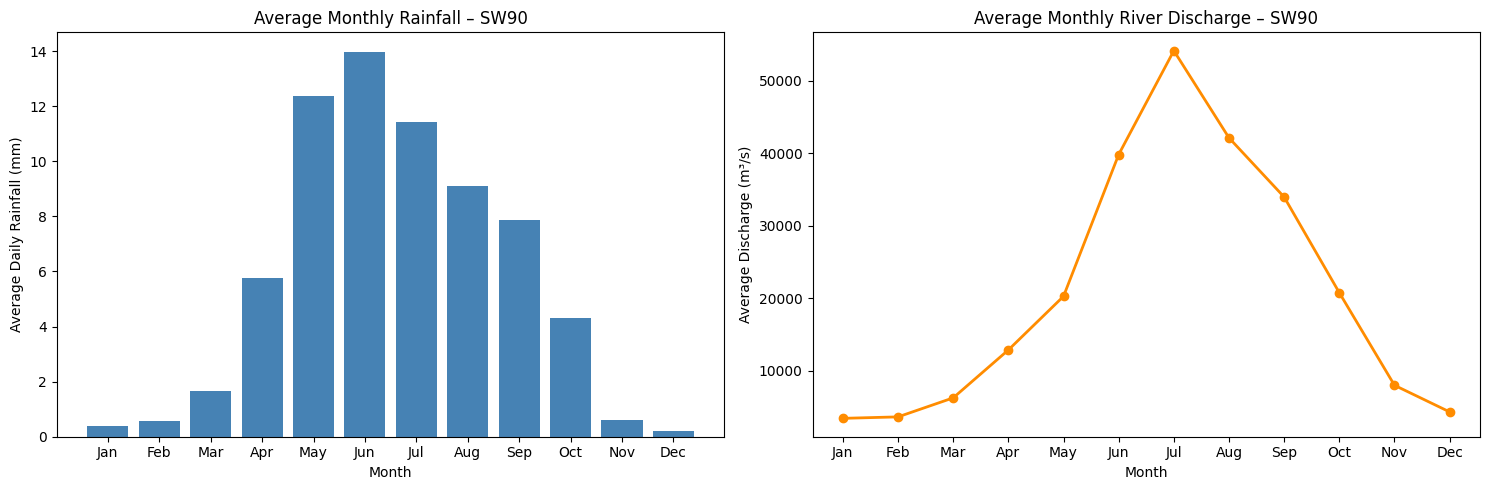

In [98]:
sw90_season = sw90.copy()
sw90_season["month"] = sw90_season["date"].dt.month

# Calculate monthly averages
monthly_environment = (
    sw90_season.groupby("month")
    .agg(
        avg_rainfall=("rainfall_local_mm", "mean"),
        avg_discharge=("river_discharge_m3s", "mean")).reindex(range(1, 13)))

monthly_environment.index = [calendar.month_abbr[i] for i in range(1, 13)]

display(monthly_environment)

# Plot seasonal patterns
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].bar(
    monthly_environment.index,
    monthly_environment["avg_rainfall"],
    color="steelblue")

axes[0].set_title("Average Monthly Rainfall – SW90")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Average Daily Rainfall (mm)")

axes[1].plot(
    monthly_environment.index,
    monthly_environment["avg_discharge"],
    marker="o",
    color="darkorange",
    linewidth=2)
axes[1].set_title("Average Monthly River Discharge – SW90")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average Discharge (m³/s)")

plt.tight_layout()
plt.show()

The analysis reveals distinct seasonal patterns in rainfall and river discharge at SW90 – Bahadurabad.

Average daily rainfall reaches its highest level in June, while average river discharge peaks in July. In comparison, the highest number of positive flood labels occurs in August.

These findings suggest a possible temporal relationship between rainfall, river discharge, and flood occurrence. However, the monthly patterns alone cannot establish causality or confirm a specific time lag.

The results support further investigation of historical rainfall, river discharge, and upstream environmental conditions as potential predictors of flood occurrence within the next 24 hours.

**Comparison of Environmental Conditions During Flood and Non-Flood Days**

In this analysis, I compare local rainfall, river discharge, and soil moisture between flood-labeled and non-flood-labeled days at SW90 – Bahadurabad.

The objective is to investigate whether environmental conditions differ between the two classes and identify potentially useful predictors for machine learning.

I focus on years with complete daily flood-label coverage to reduce the bias caused by incomplete historical observations.

Since the target variable represents flood occurrence within the next 24 hours, the analysis compares environmental conditions on the prediction day rather than necessarily on the day of the flood itself.

rainfall_local_mm        river_discharge_m3s            \
                          mean median                mean    median   
Flood Status                                                          
Flood                    22.21   18.2            45849.70  46291.16   
No Flood                  4.43    0.2            18234.31  11454.13   

             soil_moisture_local         
                            mean median  
Flood Status                             
Flood                       0.39   0.36  
No Flood                    0.28   0.29

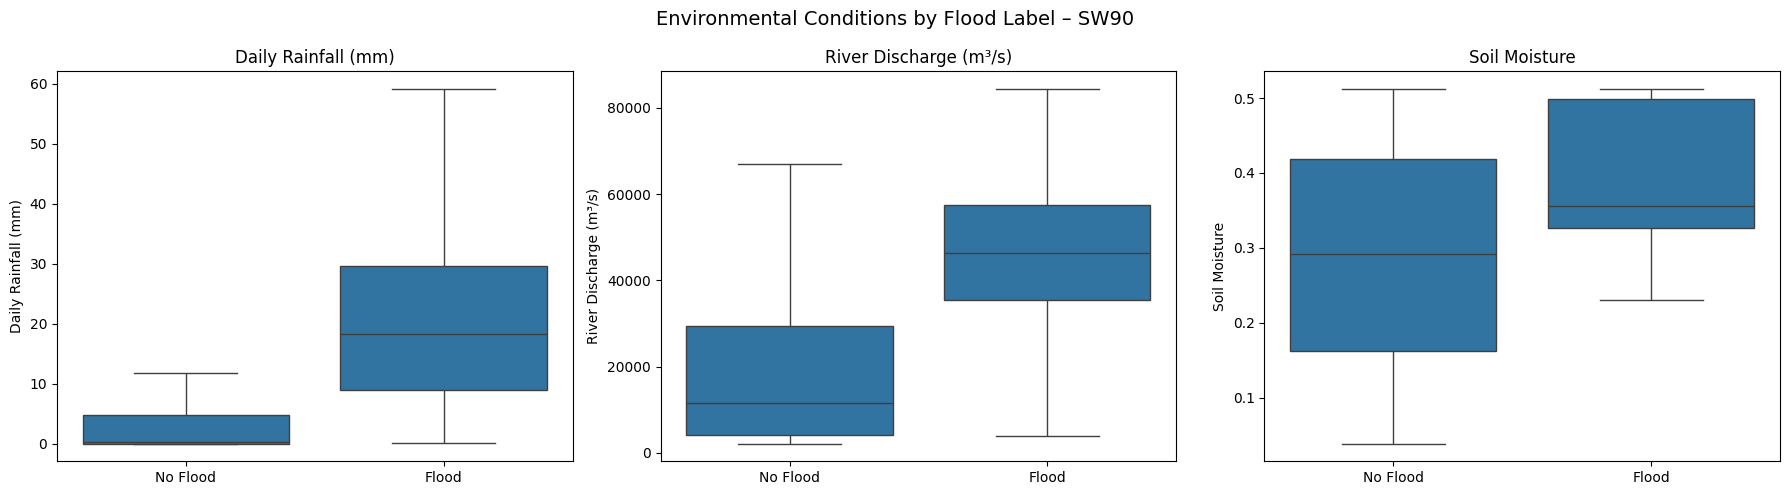

In [99]:
complete_years = [2013, 2014, 2015, 2021, 2022, 2023, 2024, 2025]

sw90_comparison = sw90[
    (sw90["date"].dt.year.isin(complete_years)) &
    (sw90["flood_within_24h_label_regime"] == "observed") &
    (sw90["flood_within_24h"].isin([0, 1]))].copy()

sw90_comparison["Flood Status"] = (
    sw90_comparison["flood_within_24h"]
    .map({0: "No Flood", 1: "Flood"}))

features = {
    "rainfall_local_mm": "Daily Rainfall (mm)",
    "river_discharge_m3s": "River Discharge (m³/s)",
    "soil_moisture_local": "Soil Moisture"}

# Summary statistics
summary = sw90_comparison.groupby("Flood Status")[
    list(features.keys())].agg(["mean", "median"])

display(summary.round(2))

# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (column, label) in zip(axes, features.items()):
    sns.boxplot(
        data=sw90_comparison,
        x="Flood Status",
        y=column,
        order=["No Flood", "Flood"],
        showfliers=False,
        ax=ax)

    ax.set_title(label)
    ax.set_xlabel("")
    ax.set_ylabel(label)

plt.suptitle("Environmental Conditions by Flood Label – SW90",fontsize=14)

plt.tight_layout()
plt.show()

The boxplot analysis reveals noticeable differences in environmental conditions between flood-labeled and non-flood-labeled days at SW90 – Bahadurabad.

Daily rainfall is substantially higher on days associated with positive flood labels, with a median of approximately 18 mm compared to nearly 0 mm for non-flood-labeled days.

River discharge shows an even more pronounced difference, with median values of approximately 46,000 m³/s for positive flood labels and 12,000 m³/s for negative labels.

Soil moisture is also generally higher in the positive flood-label group, although the distributions overlap.

These findings suggest that rainfall, river discharge, and soil moisture may be useful predictors of flood occurrence within the next 24 hours. However, the observed differences do not establish causality or guarantee predictive performance.

The next stage of the project will evaluate these environmental variables using machine learning models, with additional experiments incorporating upstream rainfall and river discharge.

## EDA conclusion and next modeling direction

This EDA has compared target-label coverage, class balance, environmental features, mapped basins, and a candidate group of stations on the Brahmaputra–Jamuna system. The next decision is **not simply to select the basin with the most positive records**. I should also check whether a candidate station has enough confirmed negative and positive labels, complete predictors, and a plausible upstream connection.

**Possible experiments (subject to validating station links and feature timing):**

- **Model A — local baseline:** use rainfall, soil moisture, and river discharge at a selected target station.
- **Model B — upstream rainfall:** add upstream rainfall features and compare performance with Model A.
- **Model C — upstream discharge:** add appropriately lagged discharge from a verified upstream station, assessing whether it improves early-warning prediction beyond Models A and B.

For all three models, I would keep the same chronological training, validation, and testing periods; use the observed 24-hour target labels; avoid using any future information; and evaluate precision, recall, F1-score, and PR-AUC. **This is a proposed modeling plan, not a result of the EDA.**